In [125]:
import numpy as np
import matplotlib.pyplot as plt
import random

def in_intervals(x, lower, upper):
    return any(lo <= x <= hi for lo, hi in zip(lower, upper))

def jumps_until_inside(x, lower, upper, step=0.5, max_jumps=6):
    """
    x: starting value
    lower, upper: interval lists
    step: amplitude of random offset per jump
    max_jumps: safety stop
    """
    jumps = 0
    steps=[]
    offset=0
    
    while not in_intervals(x, lower, upper):
        # Random offset in [-step, step]
            offset = random.randint(-step*10, step*10)/10
            x += offset
            jumps += 1
            steps.append(offset)
            
            if jumps > max_jumps:
                return np.nan, jumps ,0 # failed to converge
        
    return x, jumps, offset



In [126]:
size=7.8

lower=np.array([0,30,60,90,120,150,180,210,240,270,300,330])
upper=lower+size

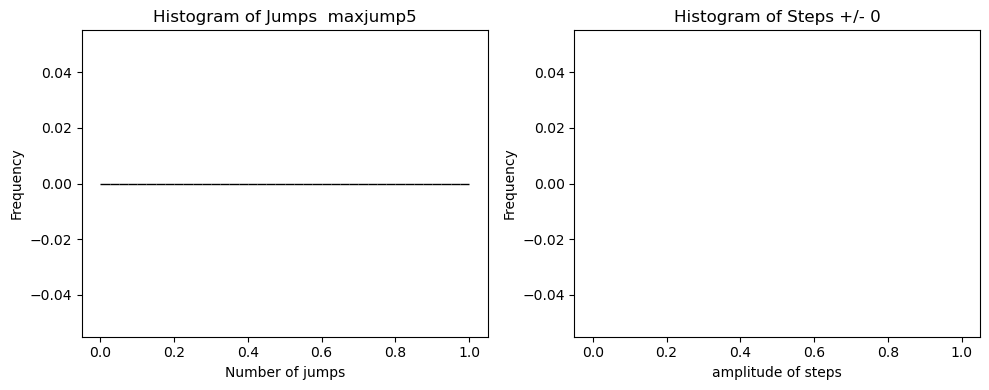

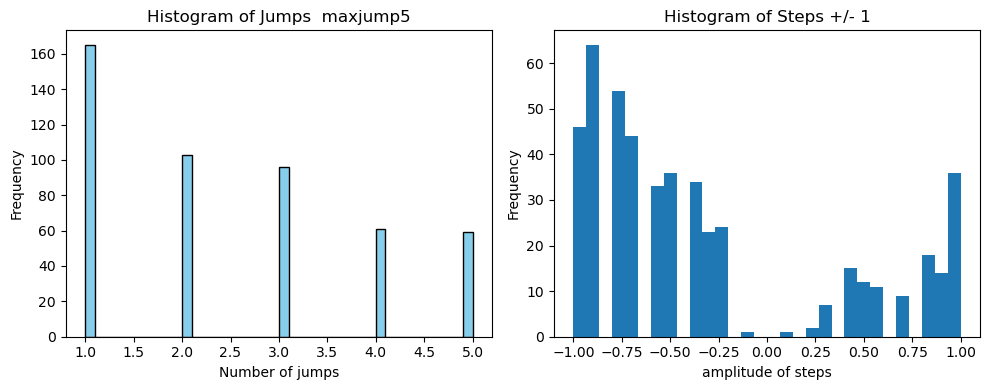

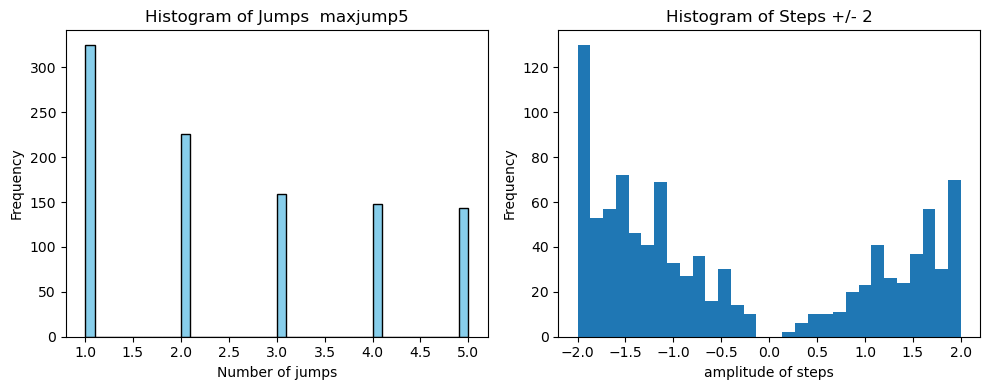

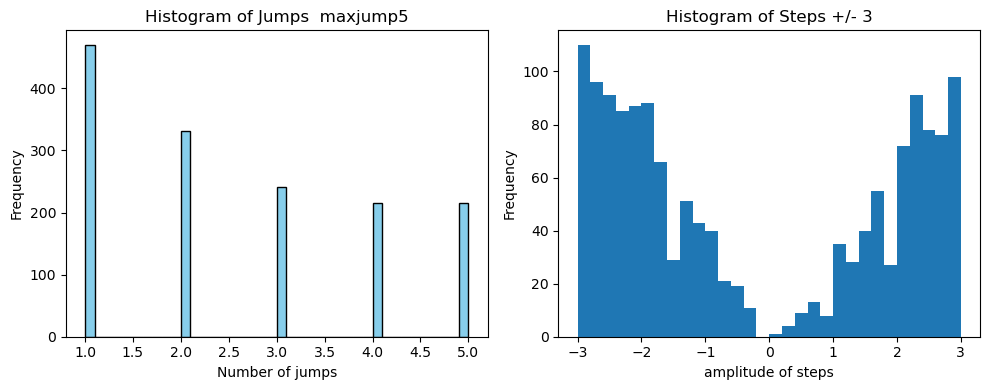

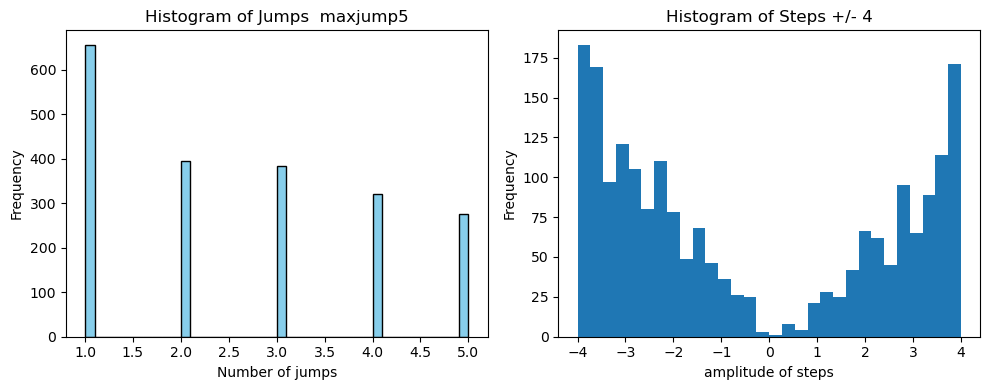

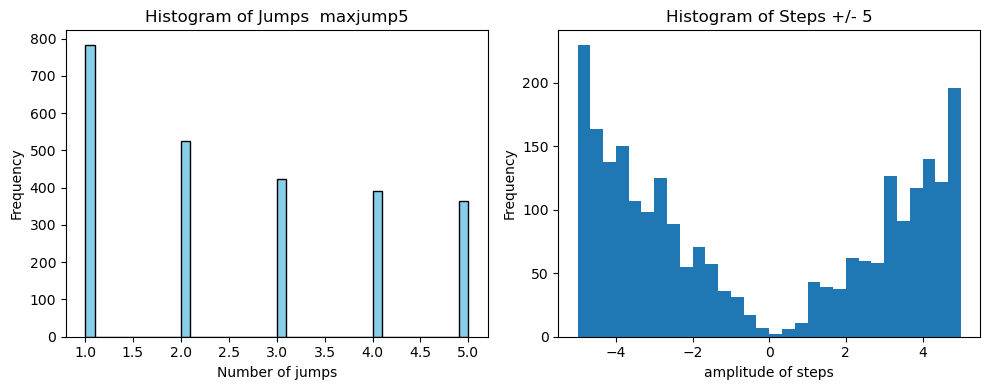

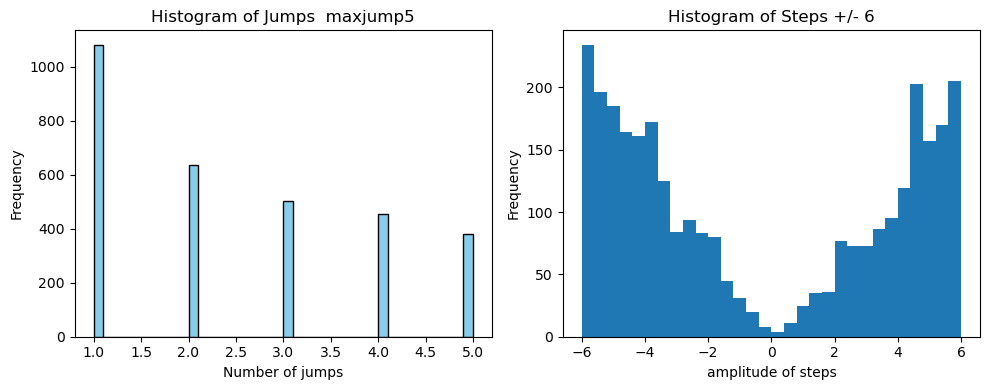

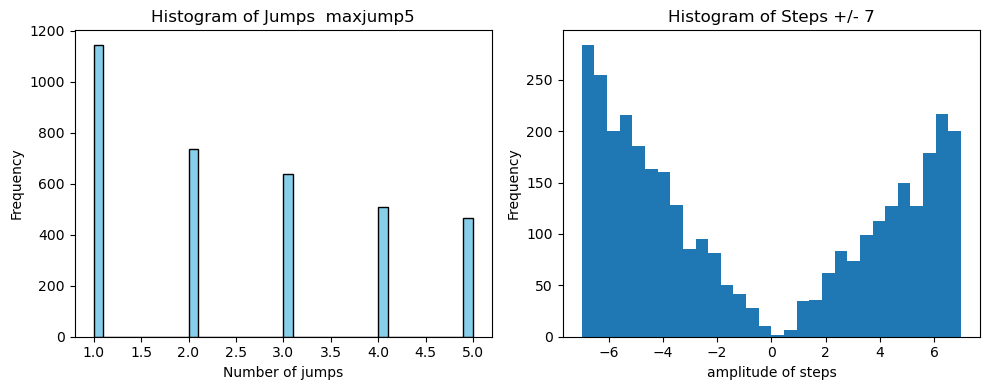

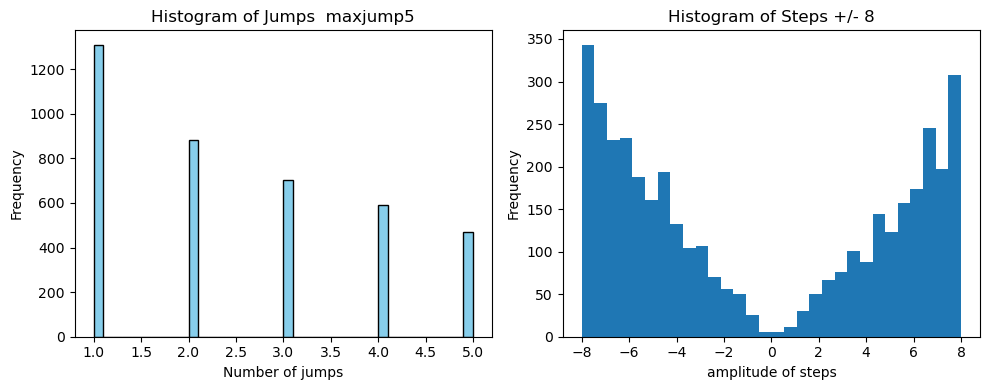

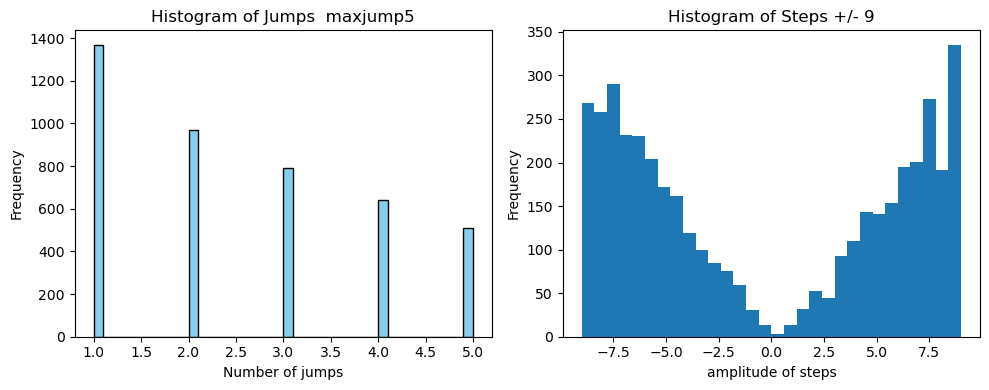

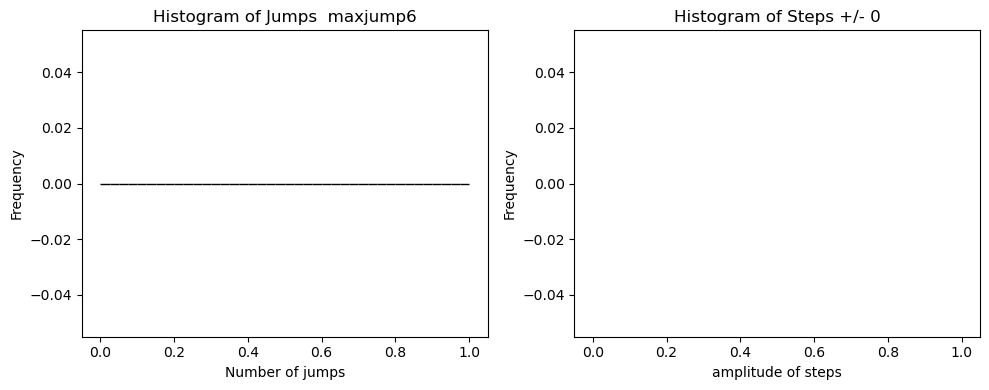

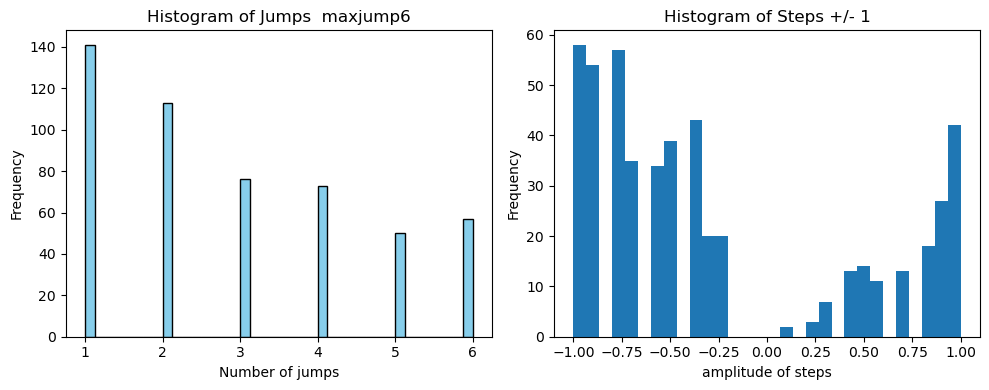

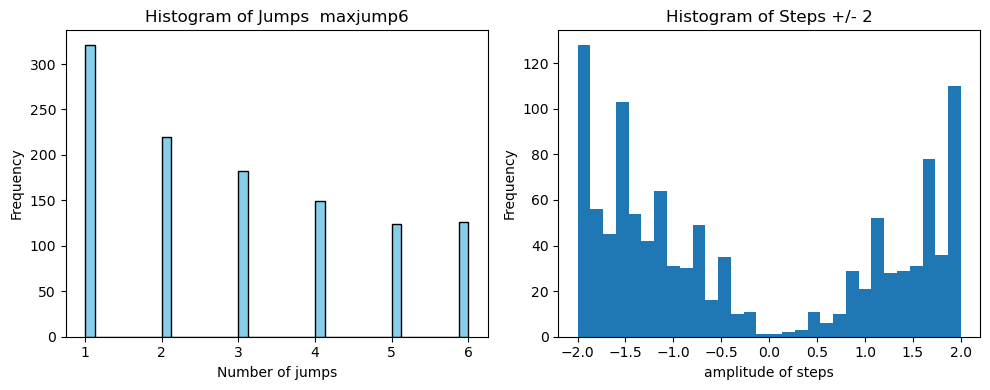

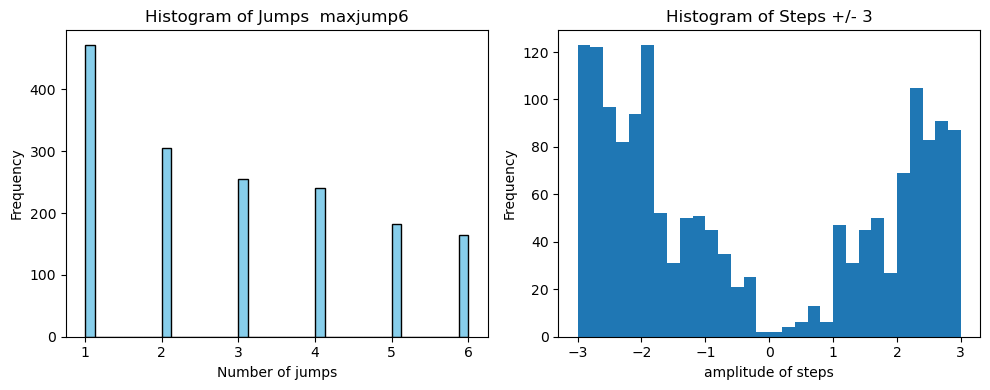

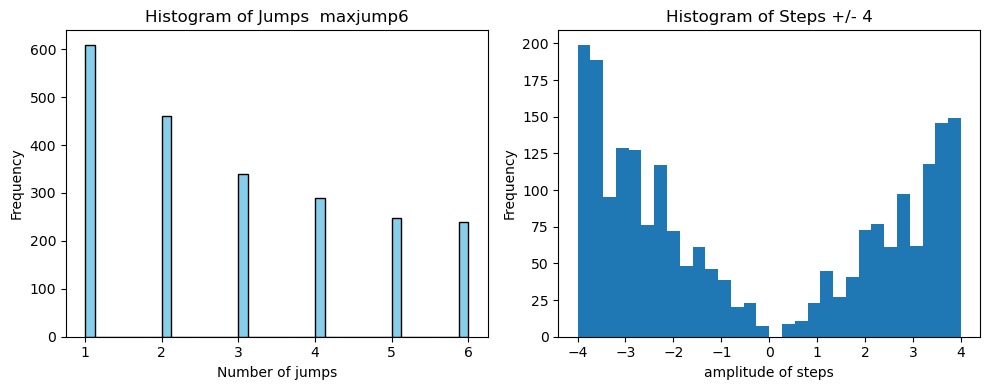

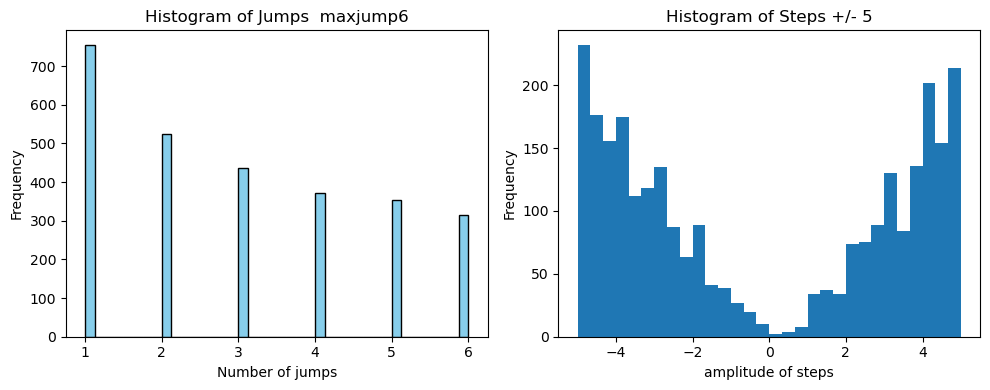

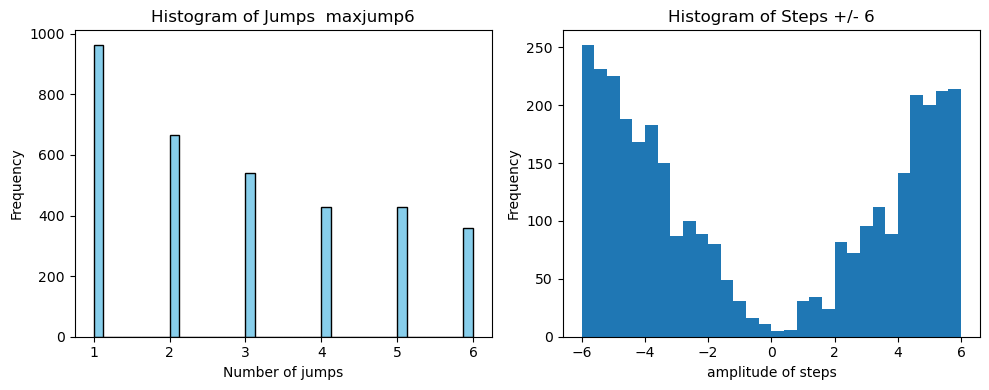

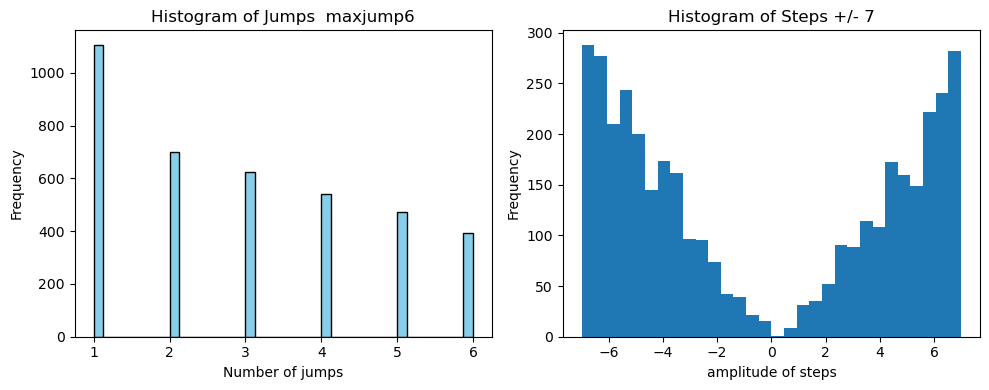

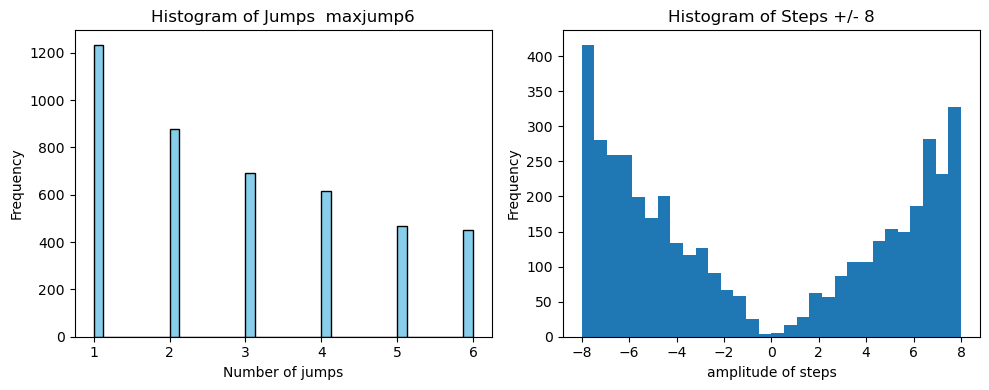

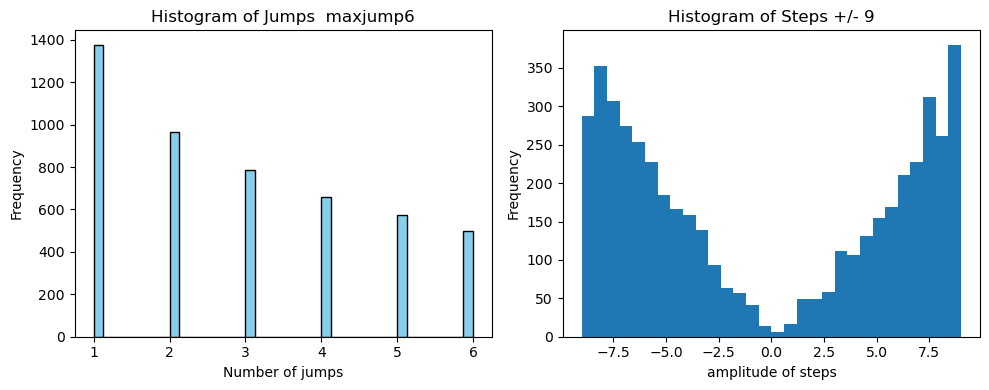

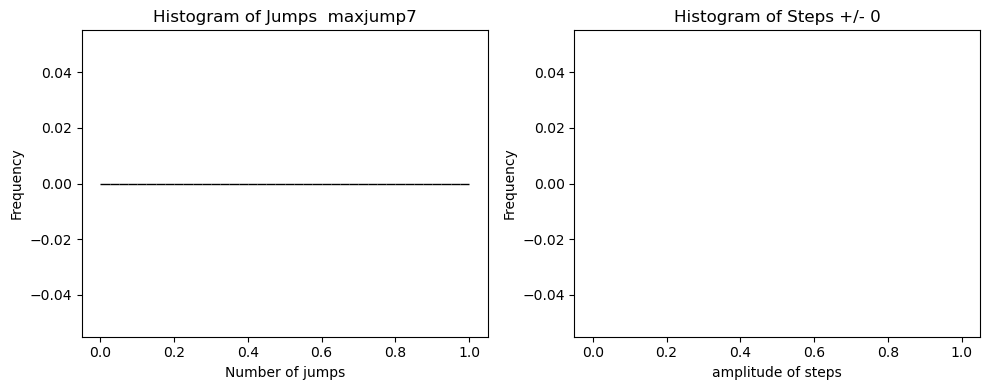

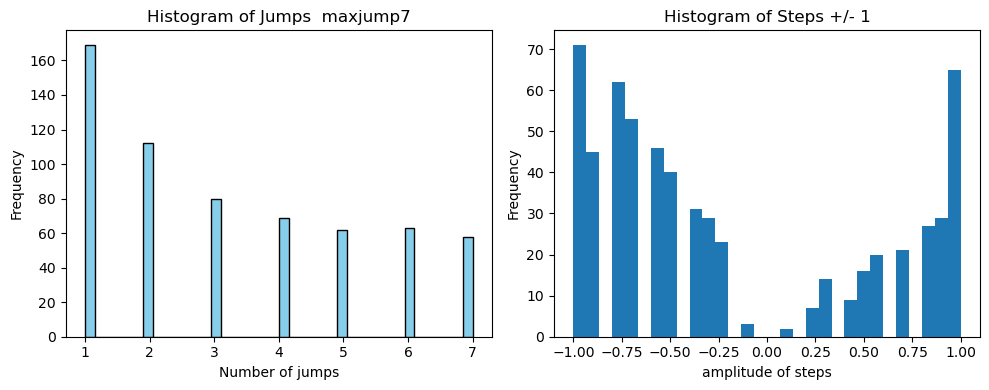

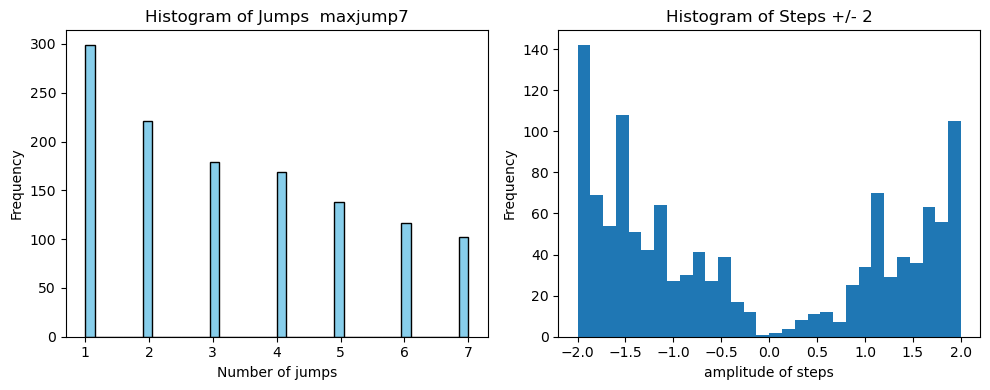

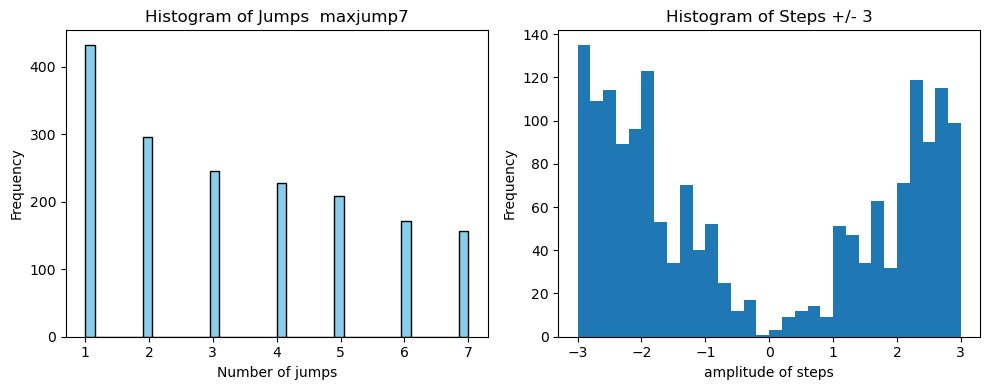

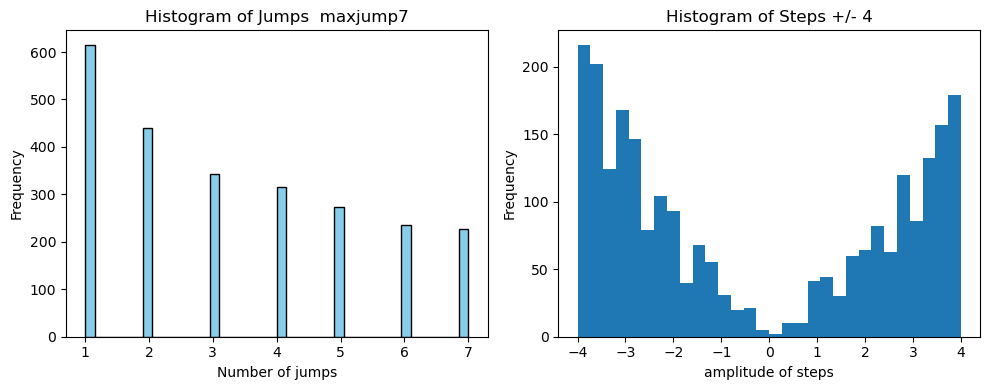

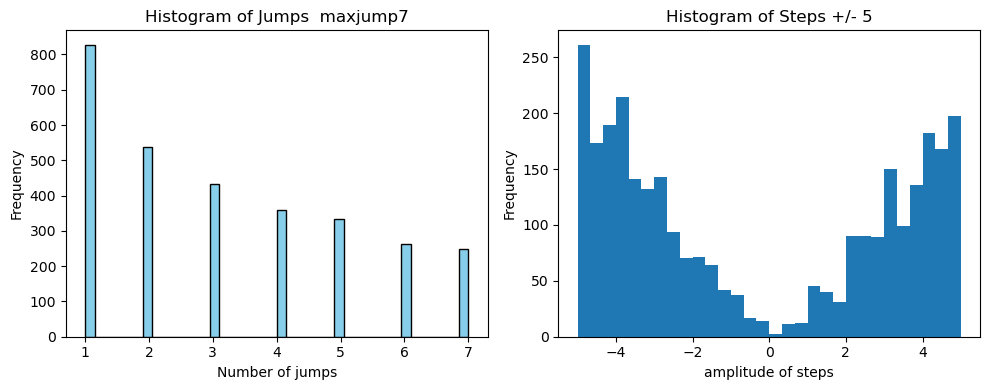

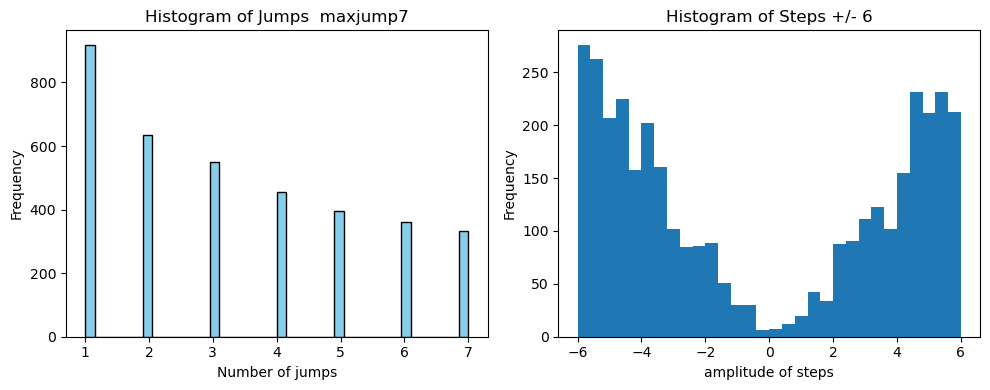

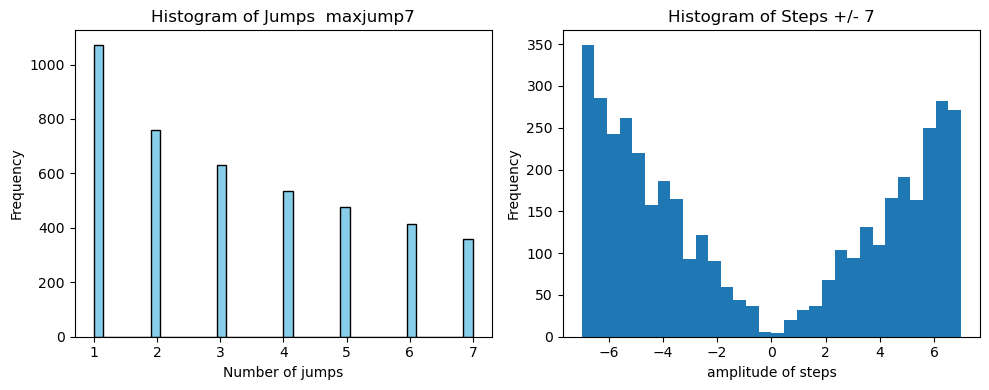

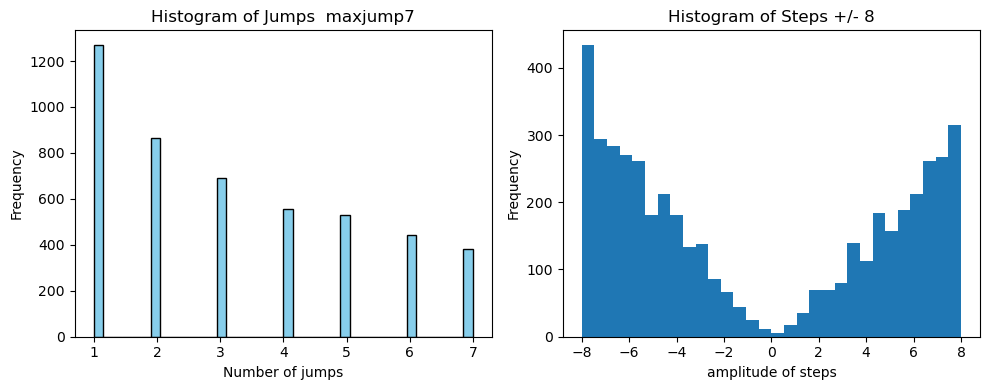

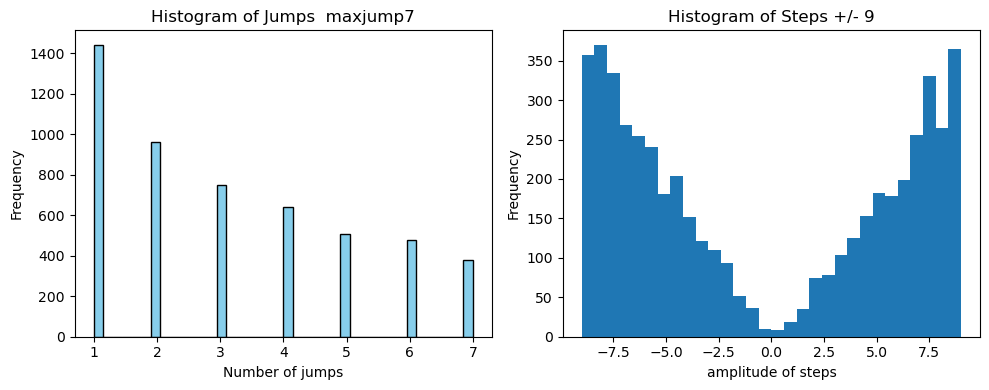

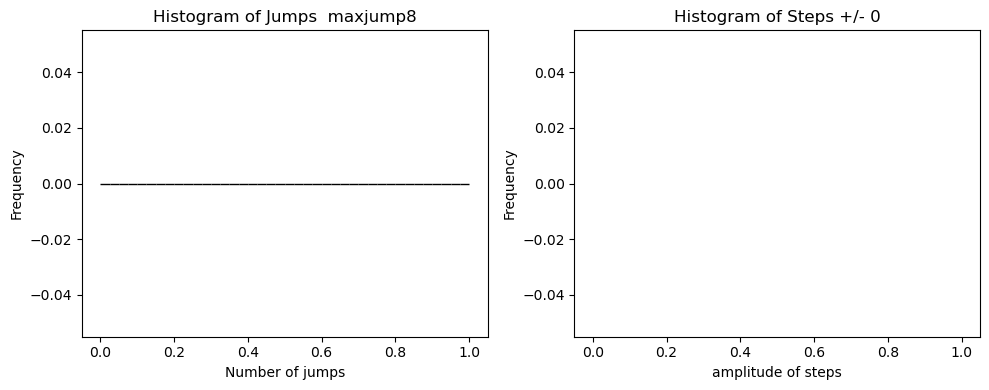

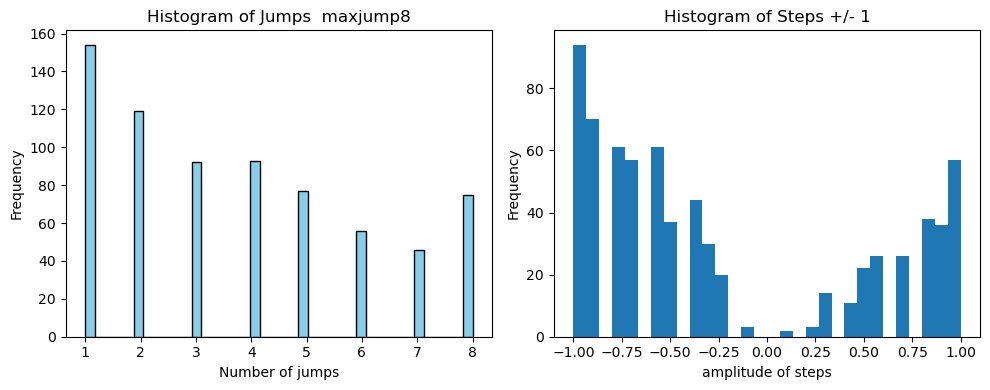

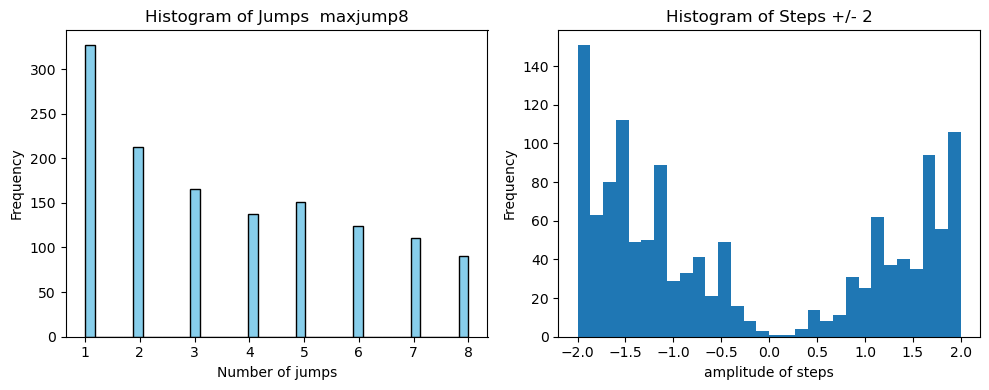

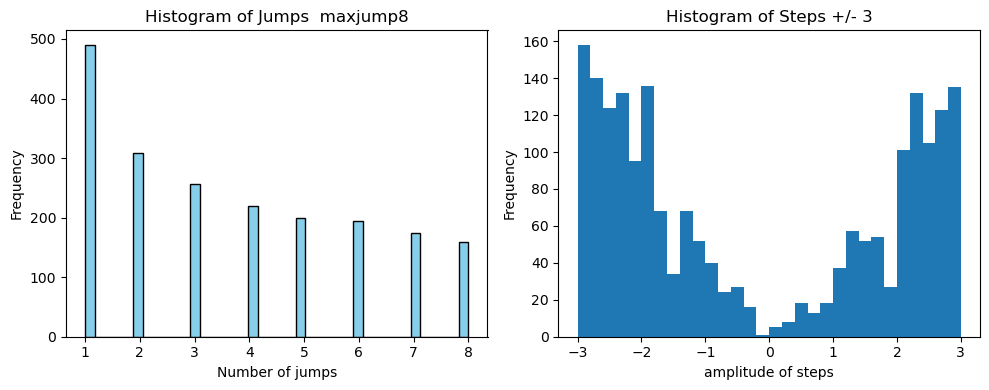

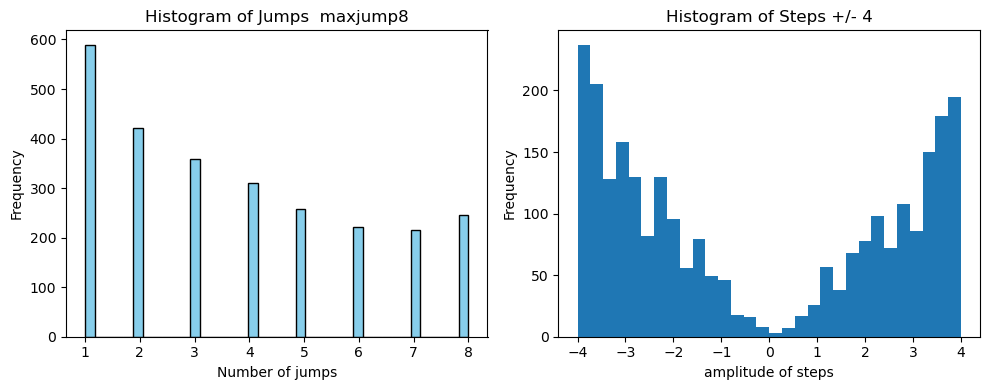

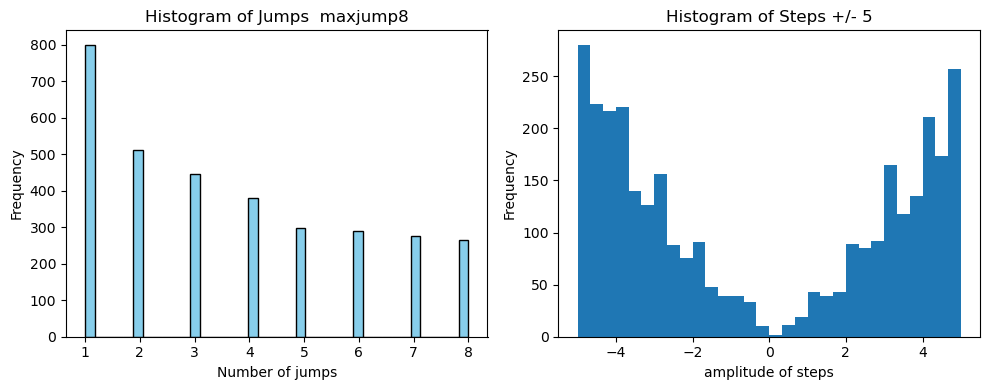

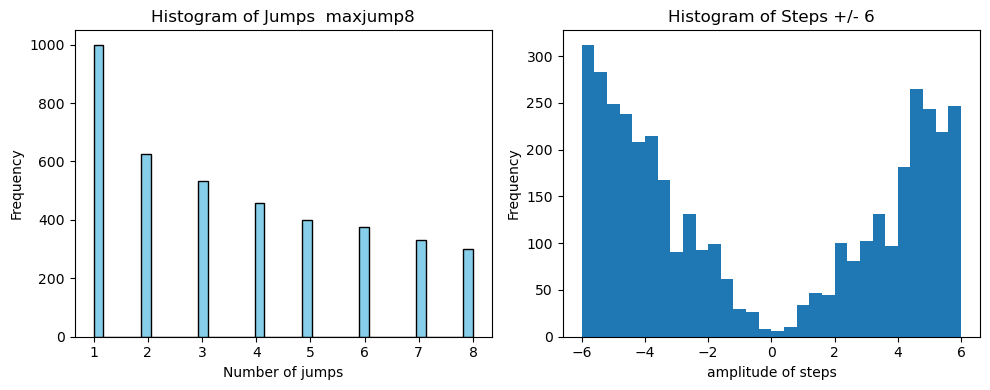

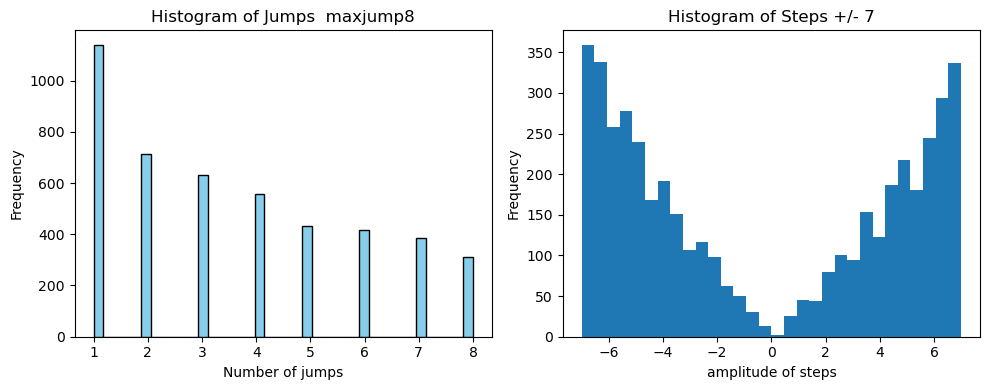

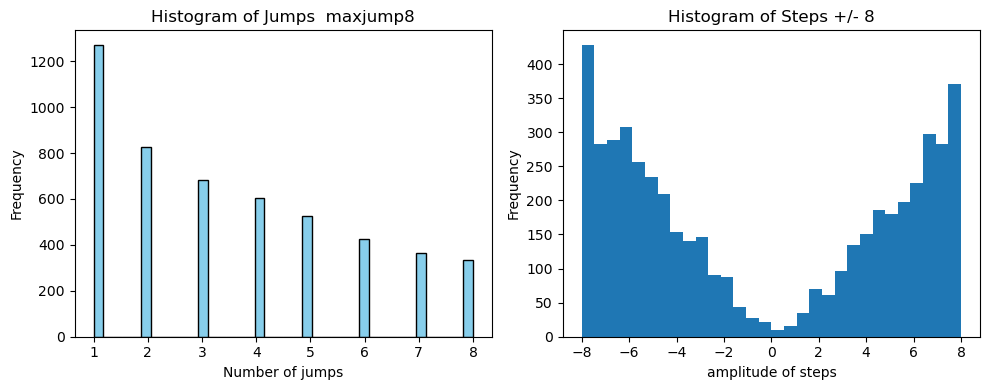

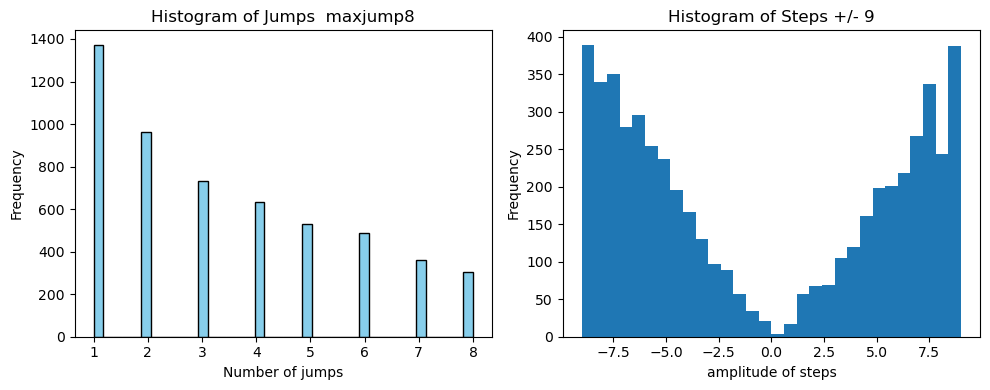

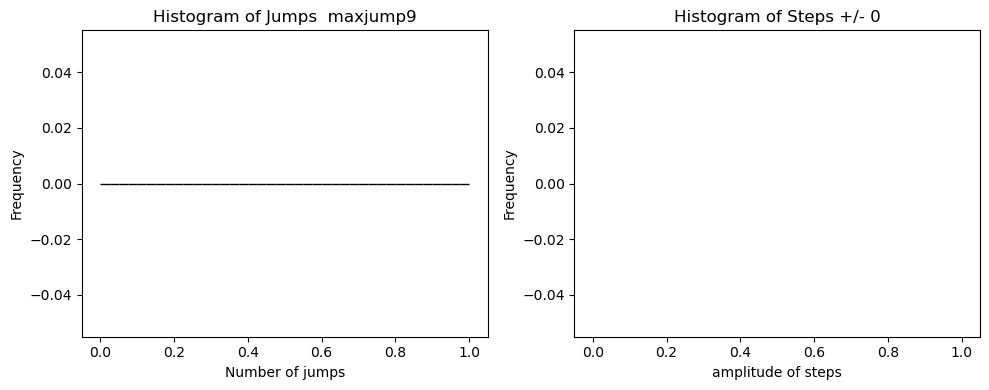

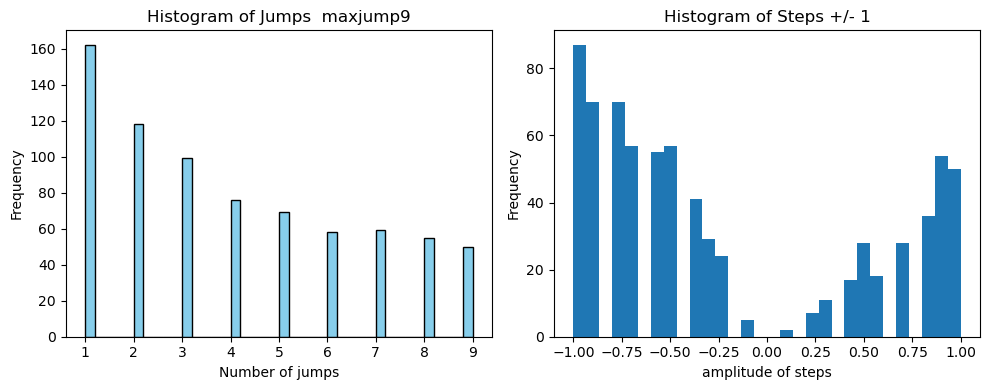

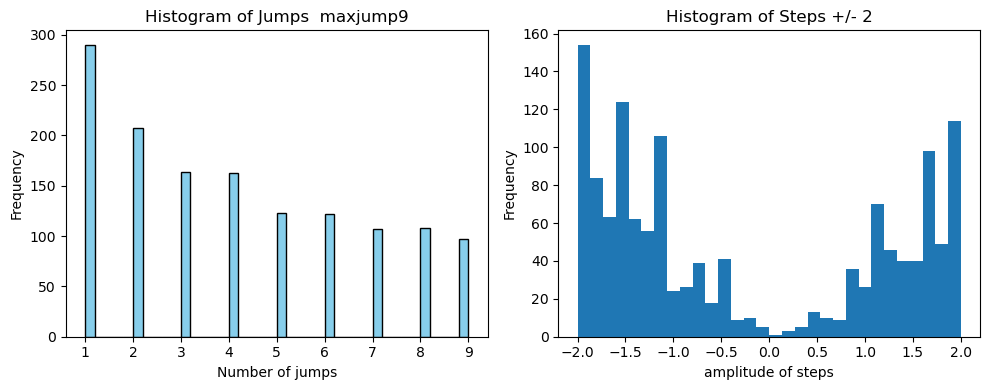

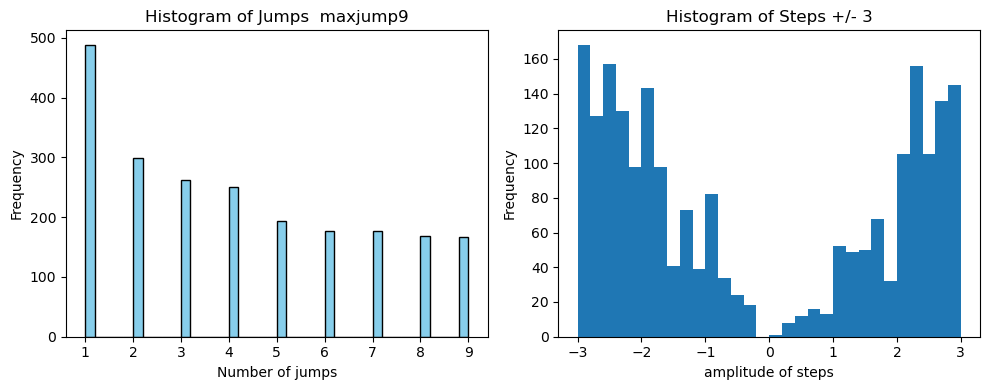

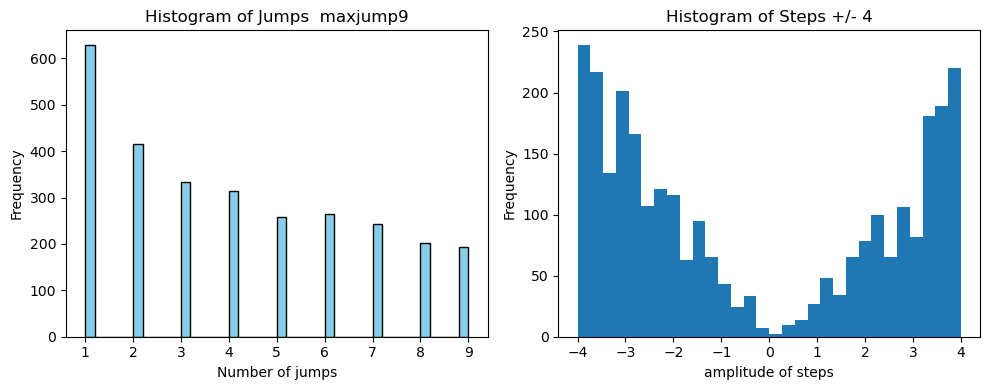

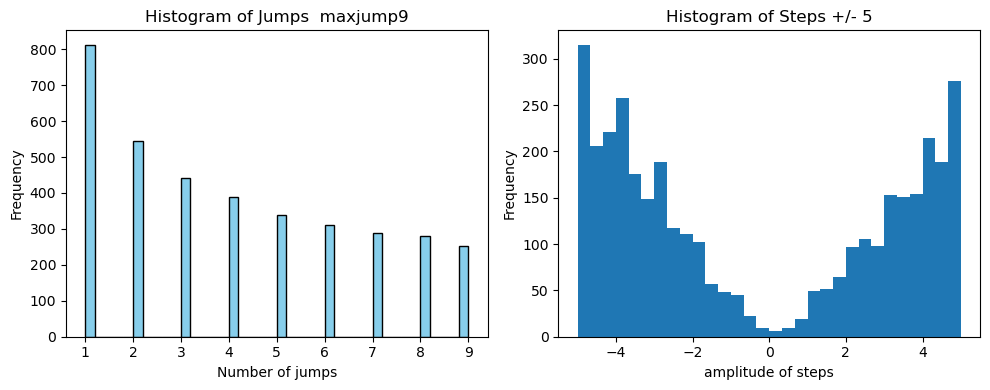

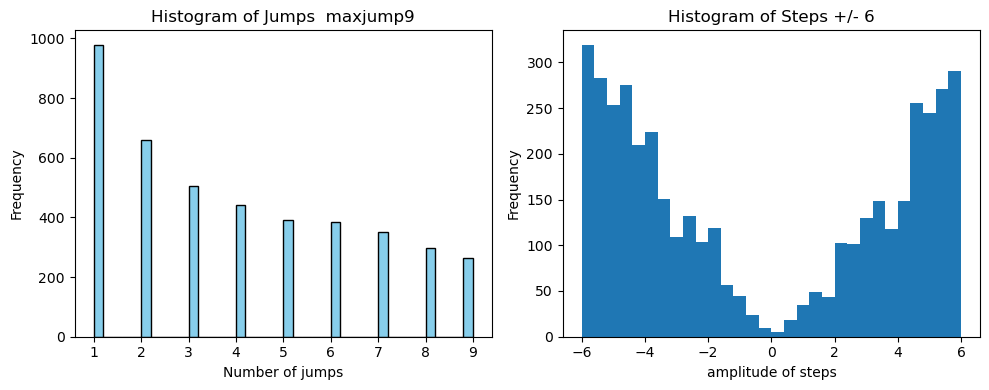

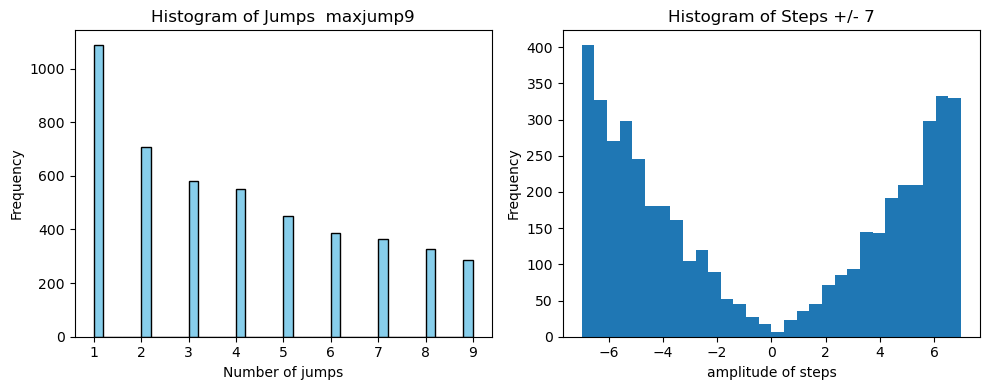

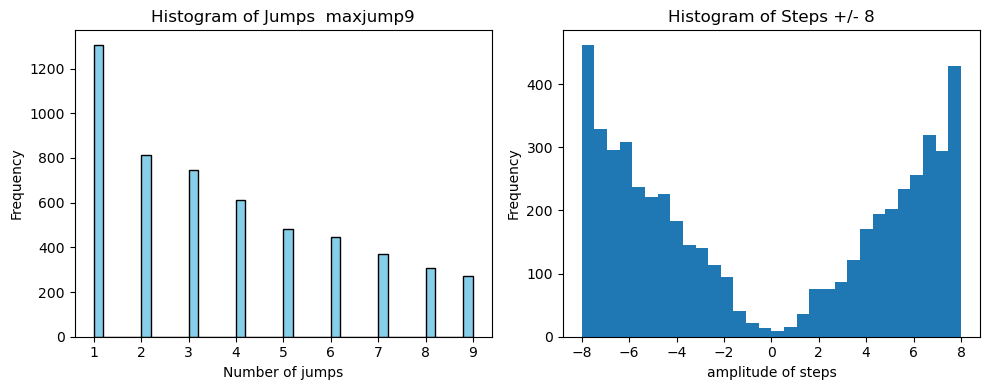

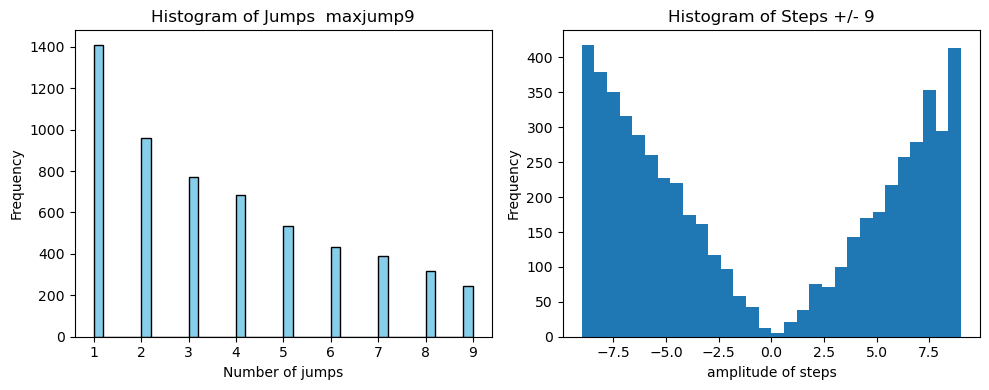

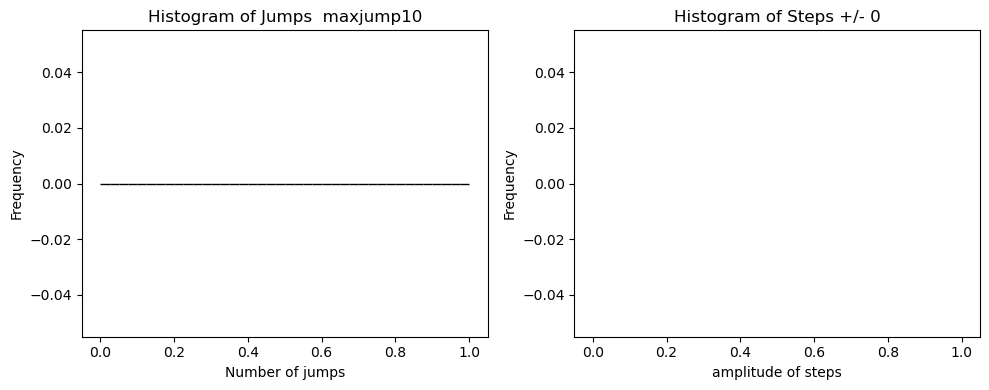

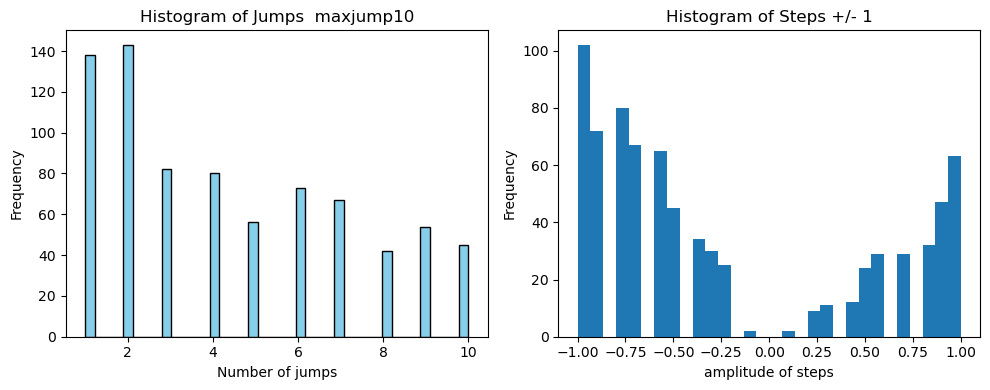

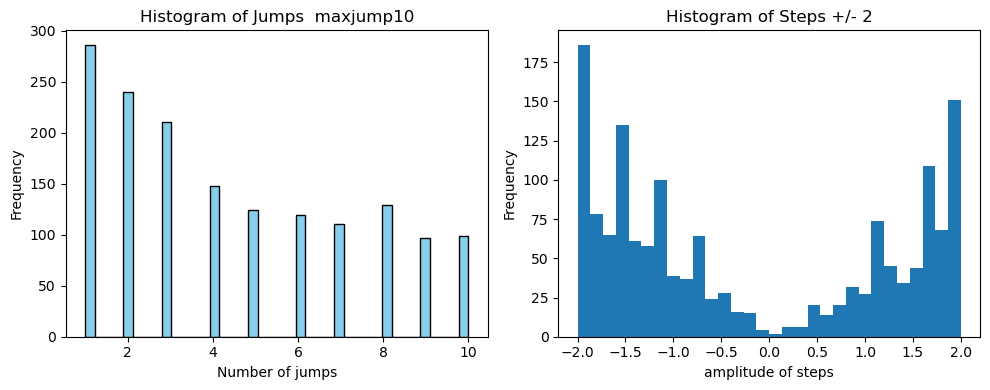

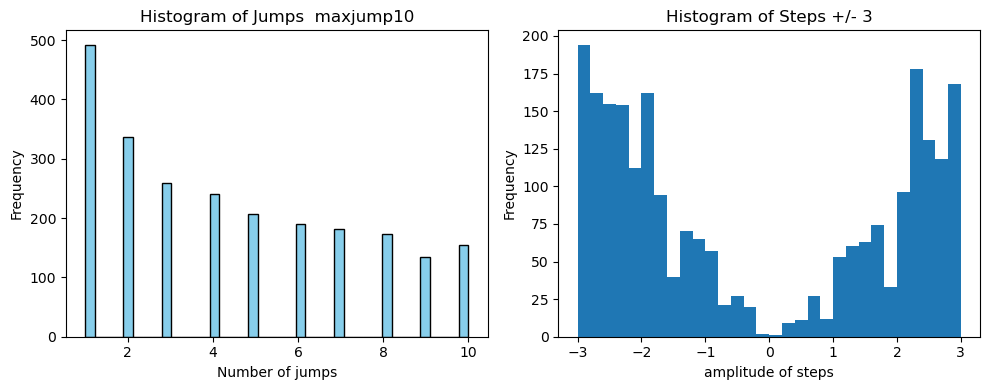

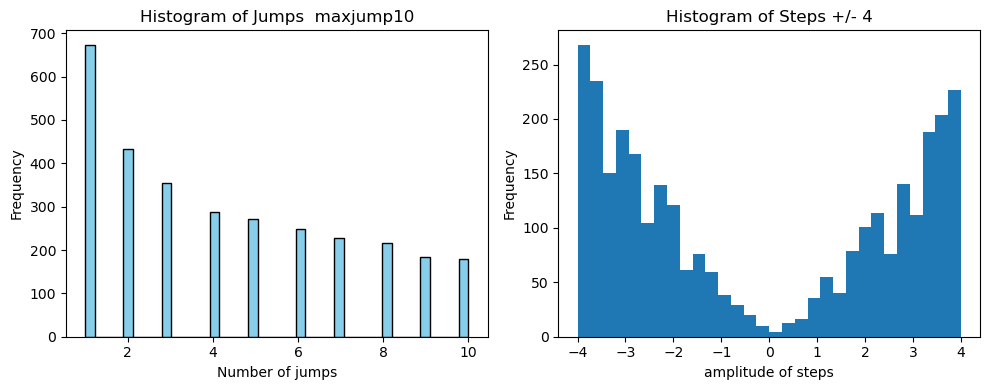

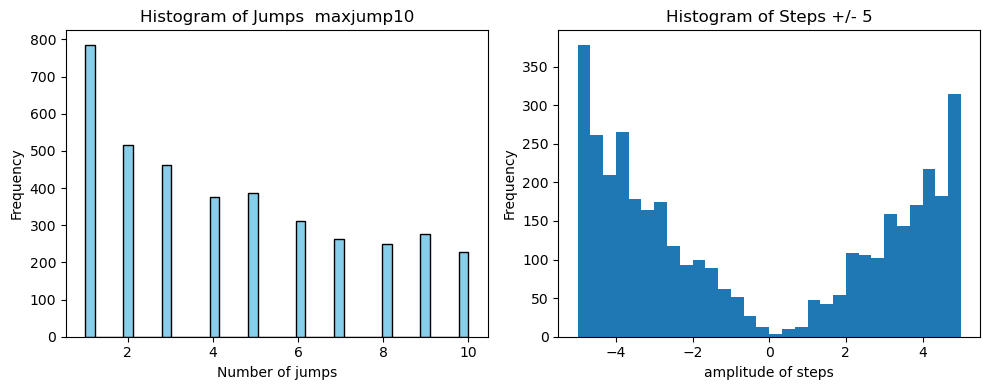

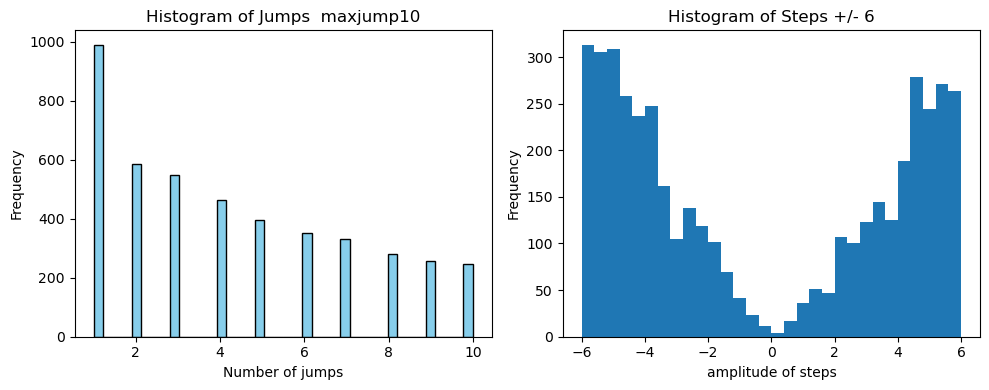

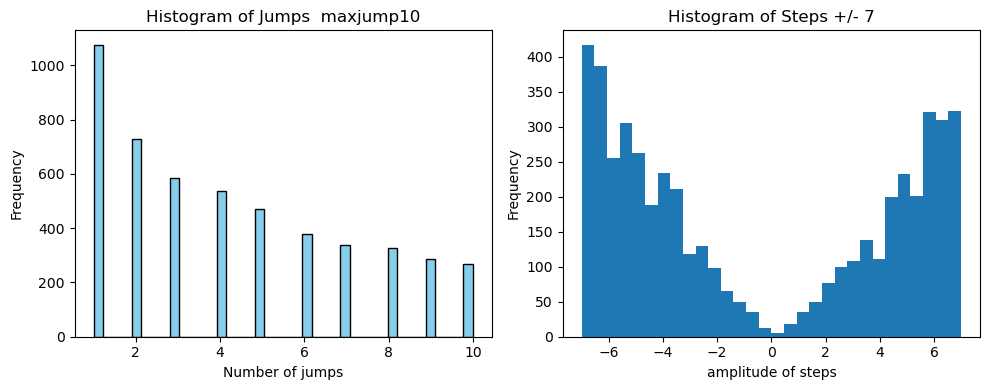

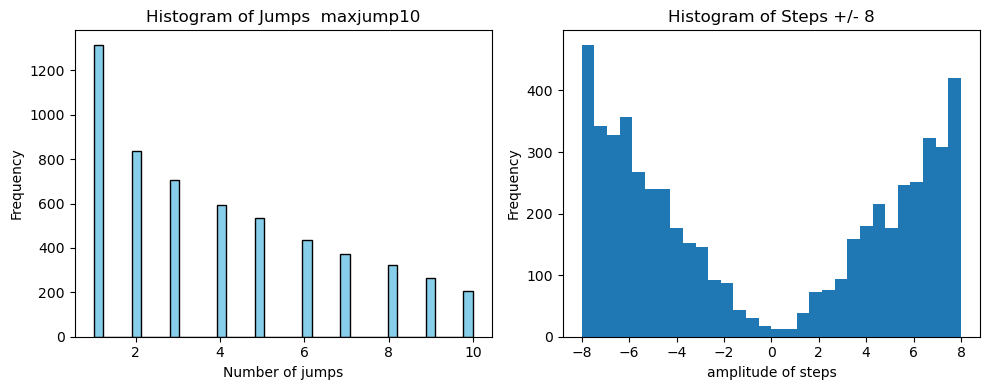

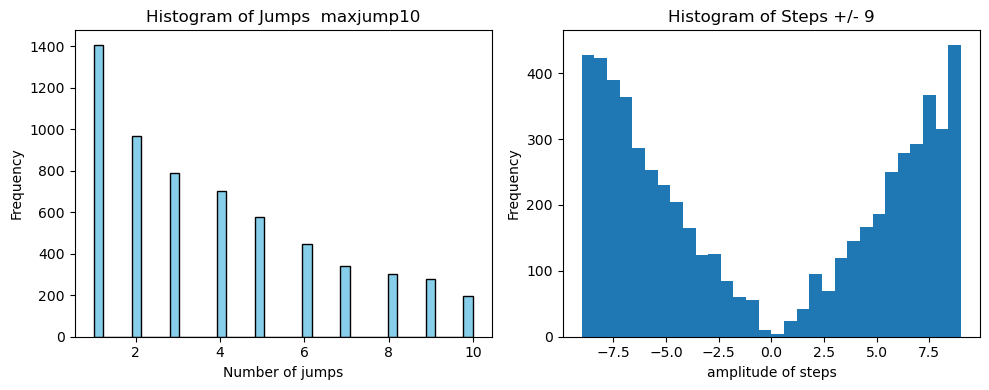

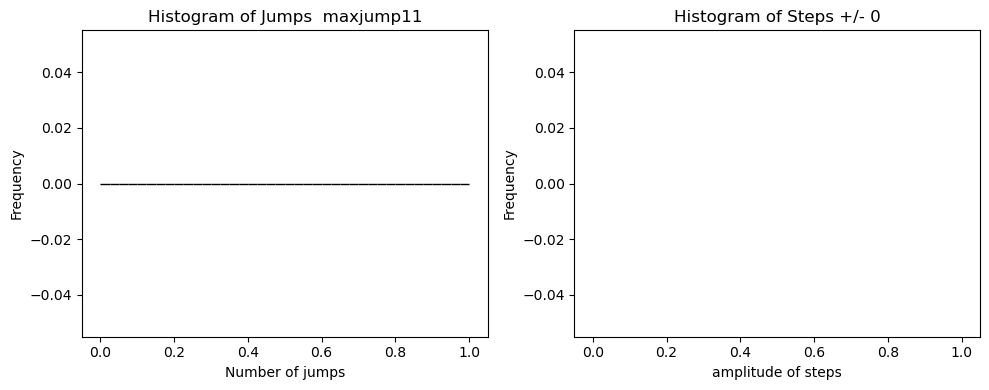

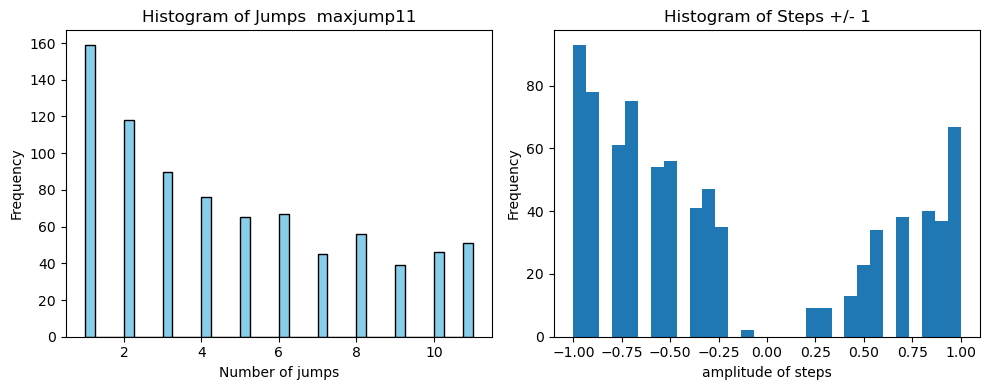

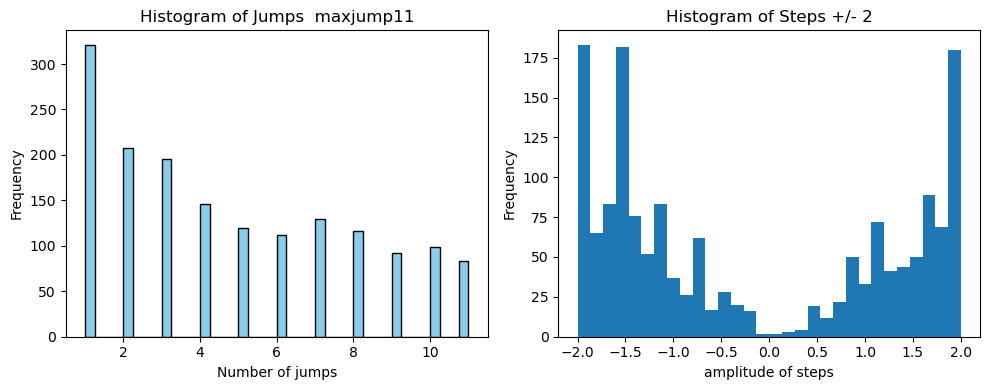

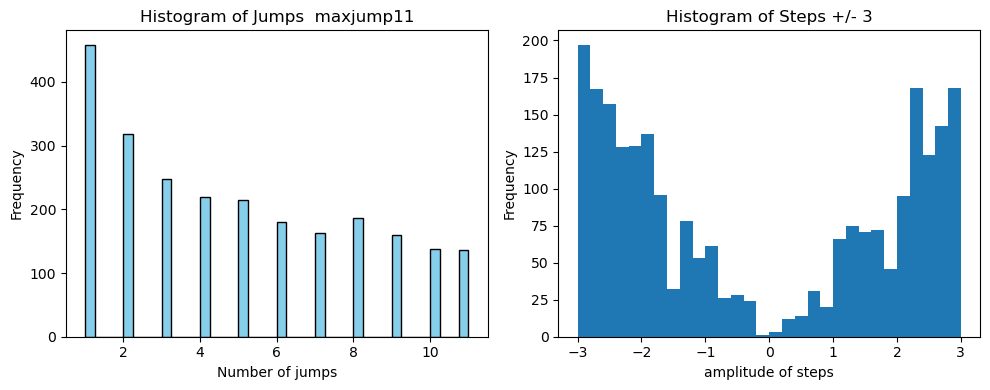

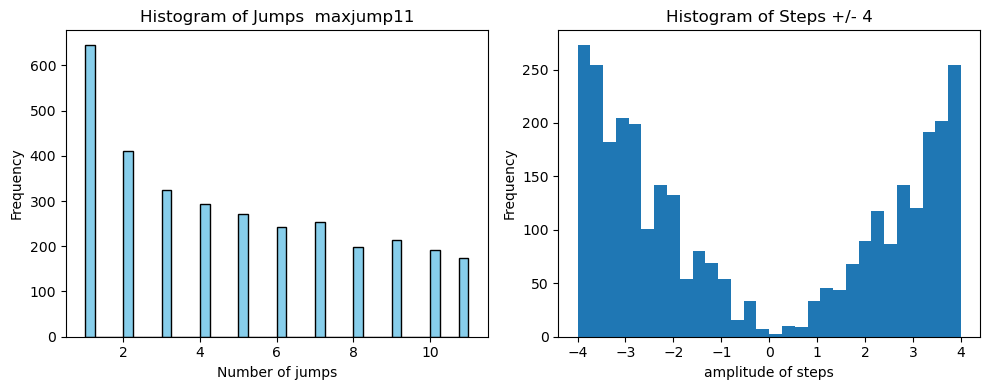

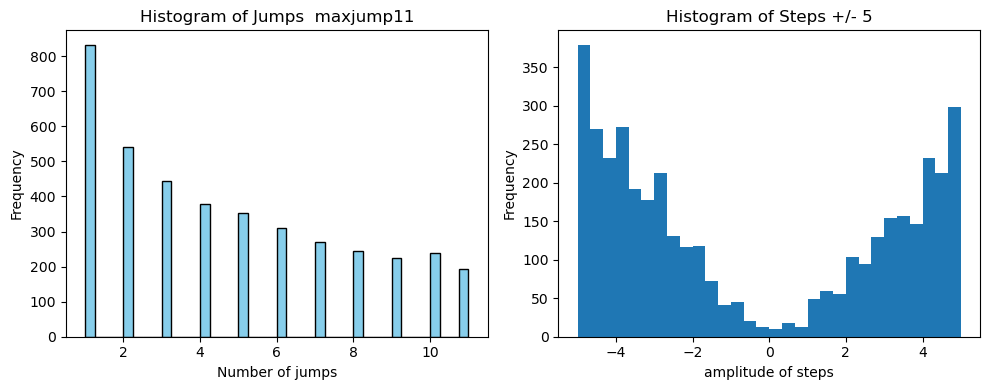

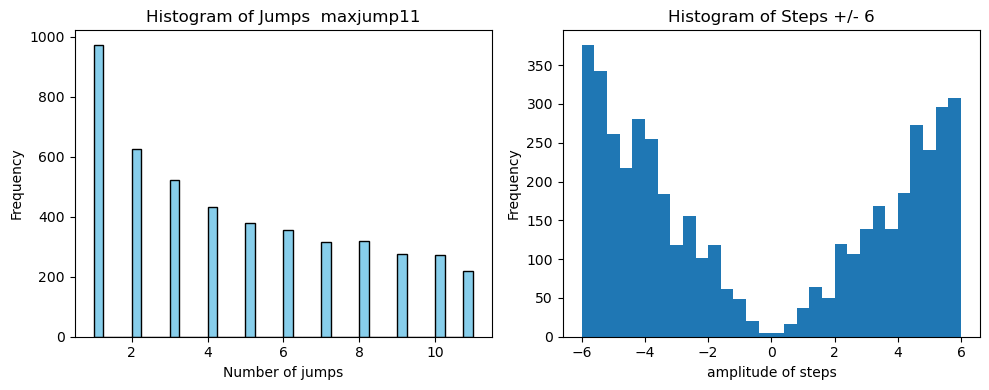

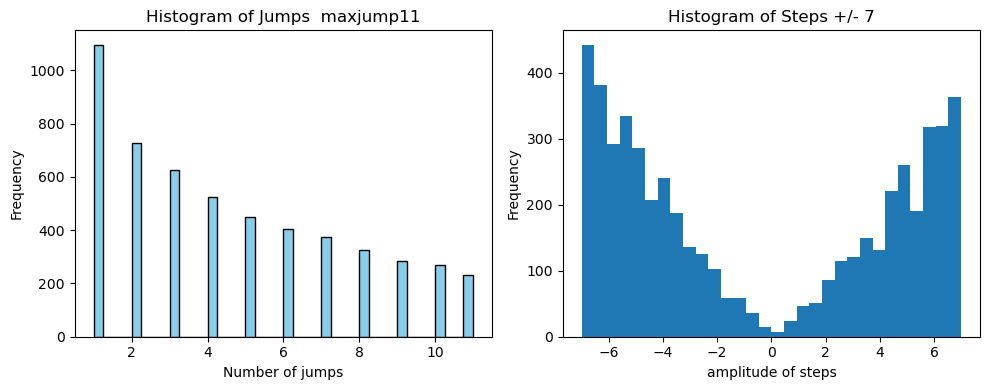

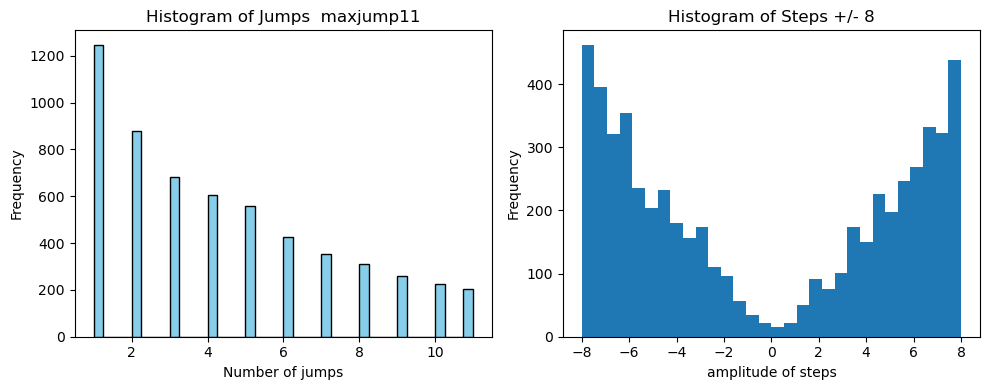

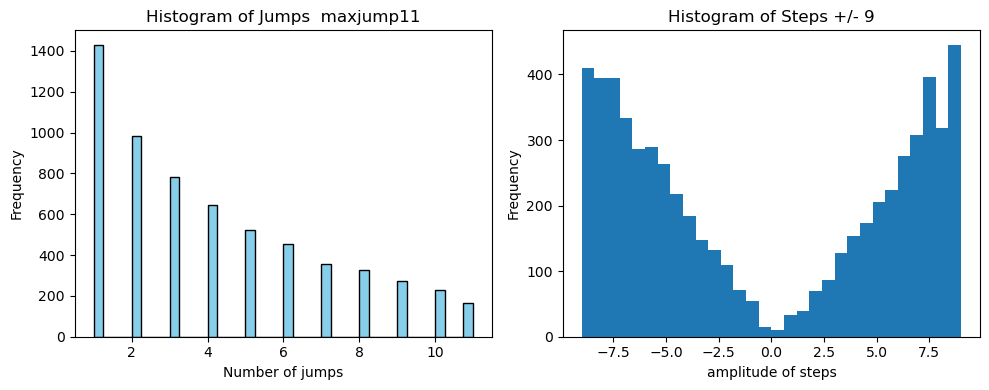

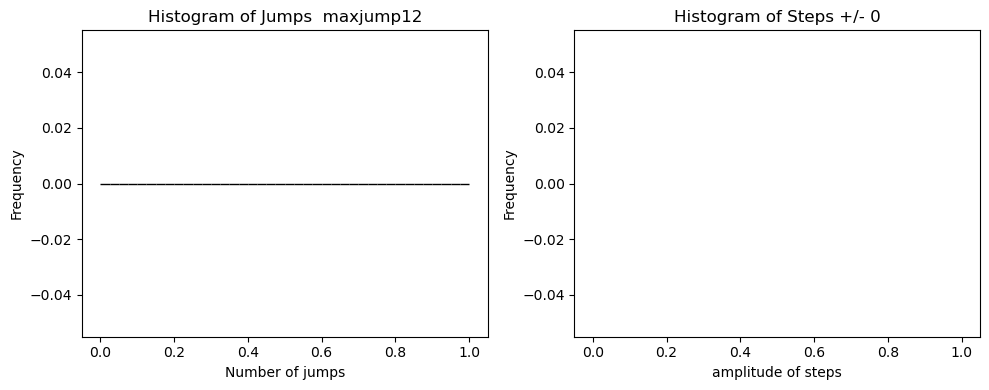

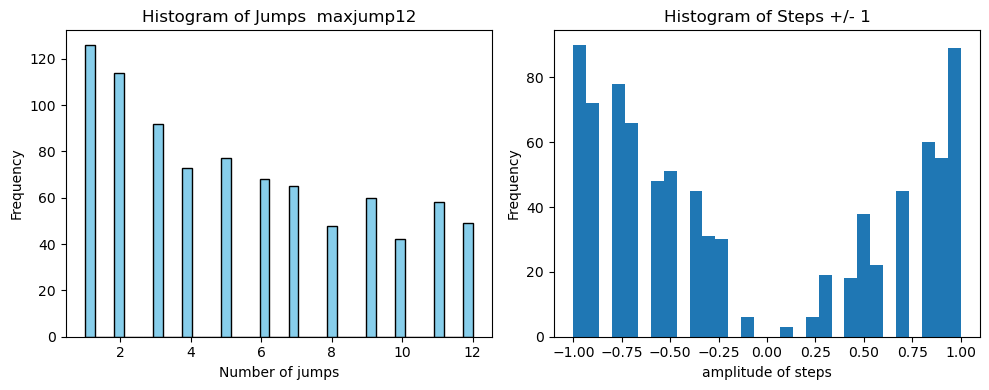

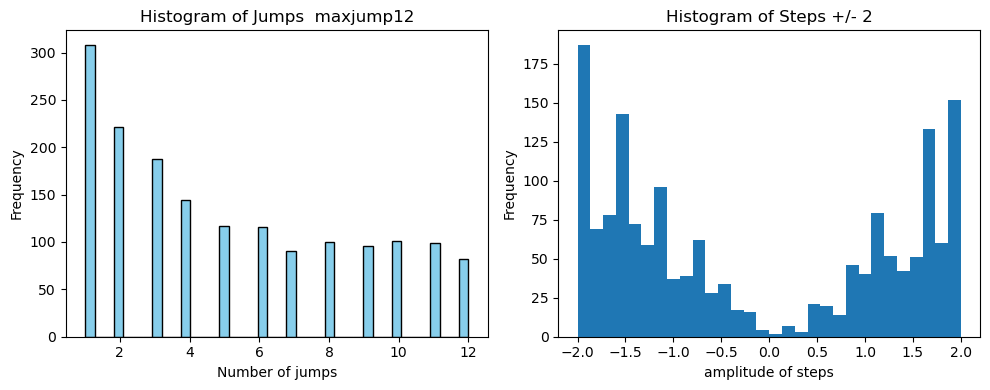

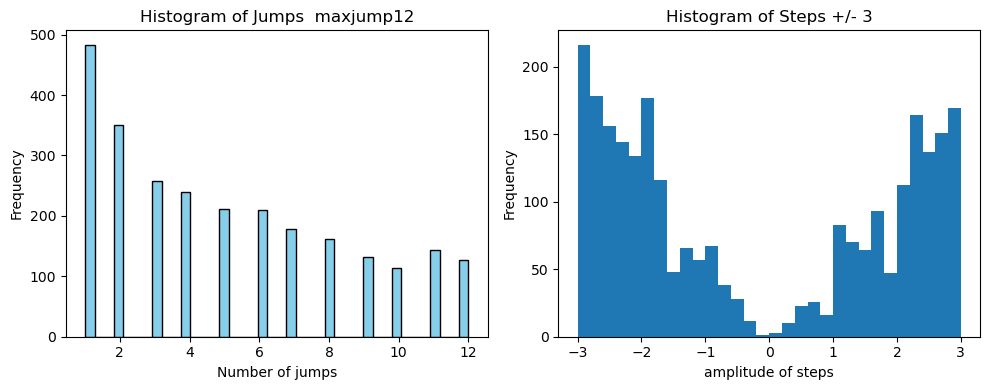

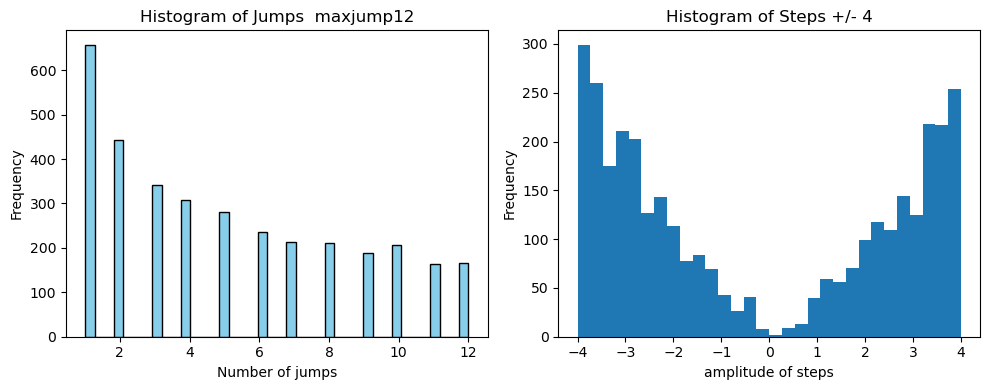

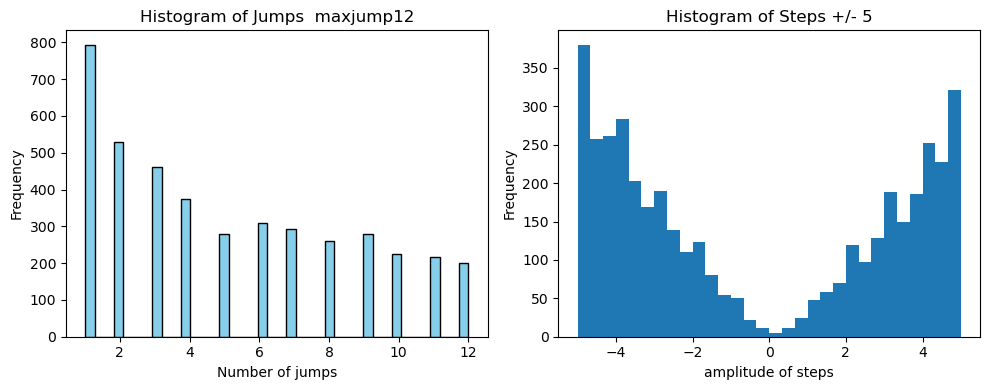

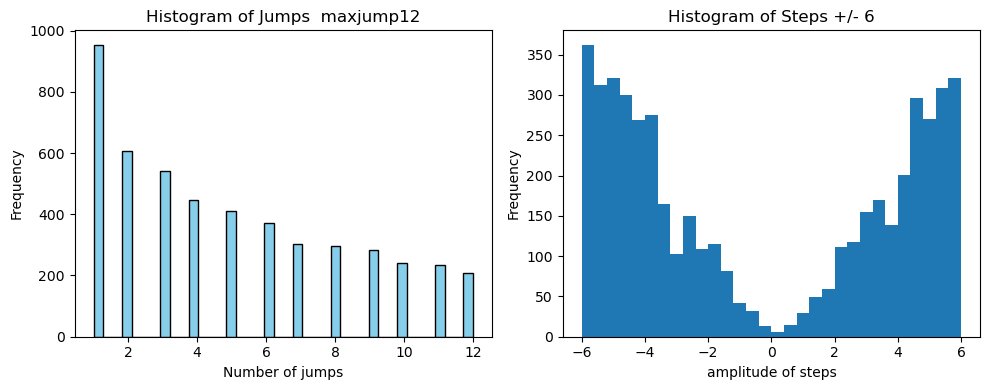

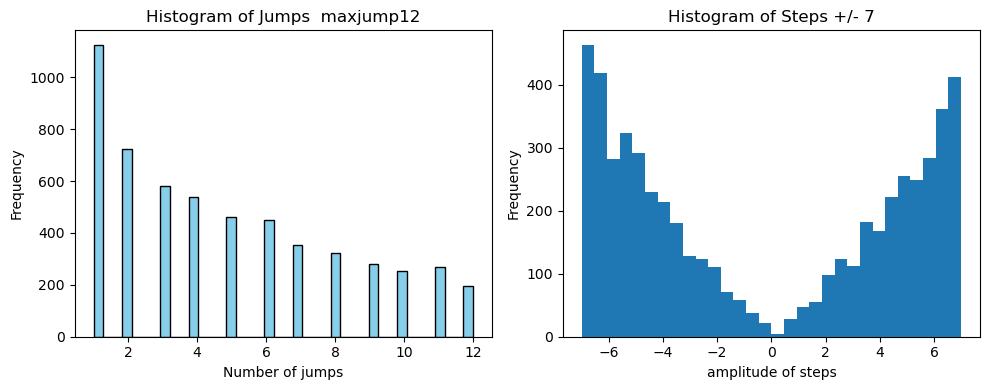

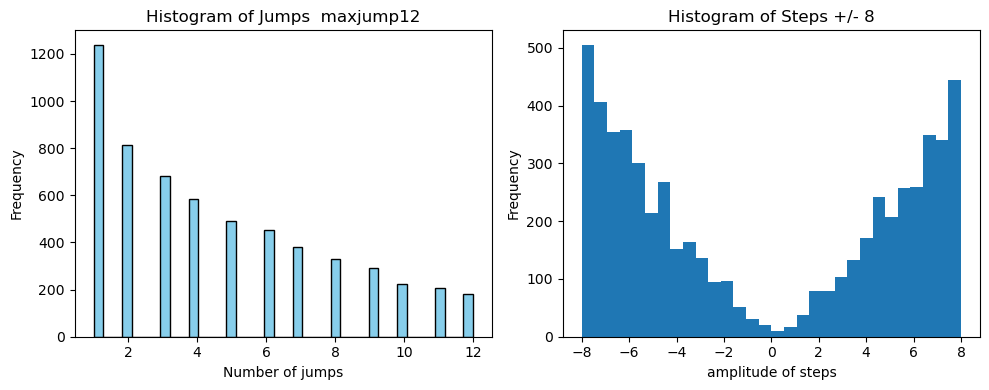

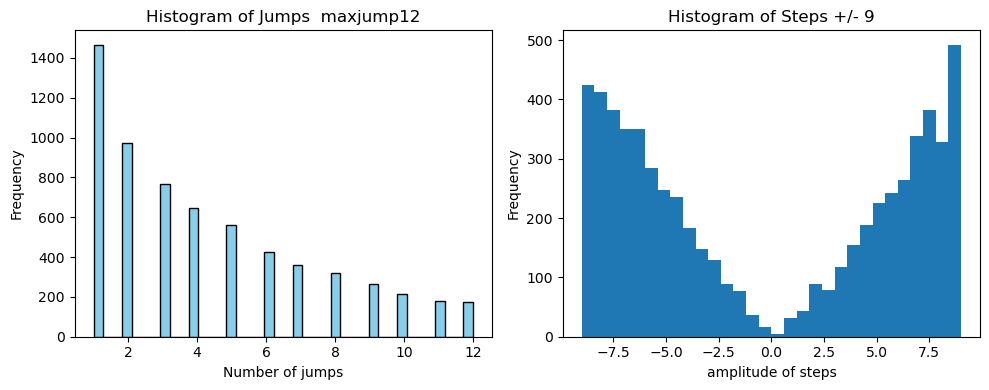

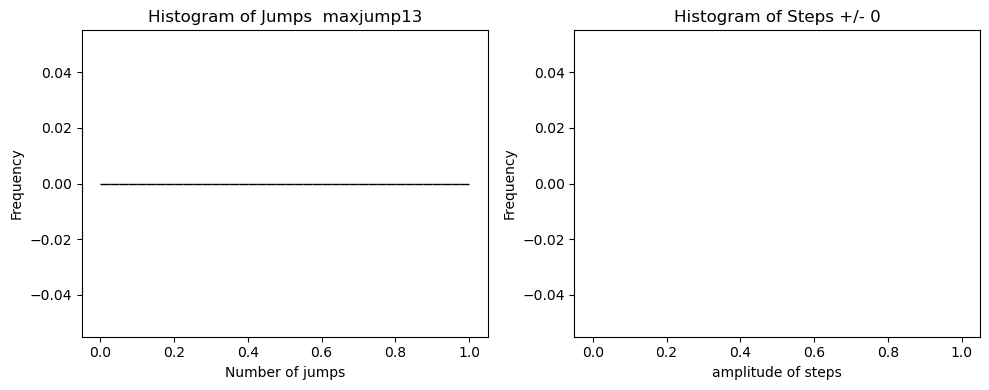

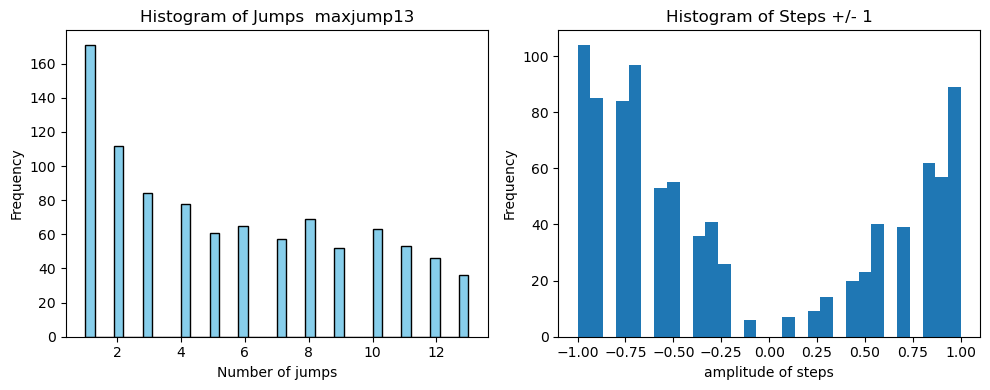

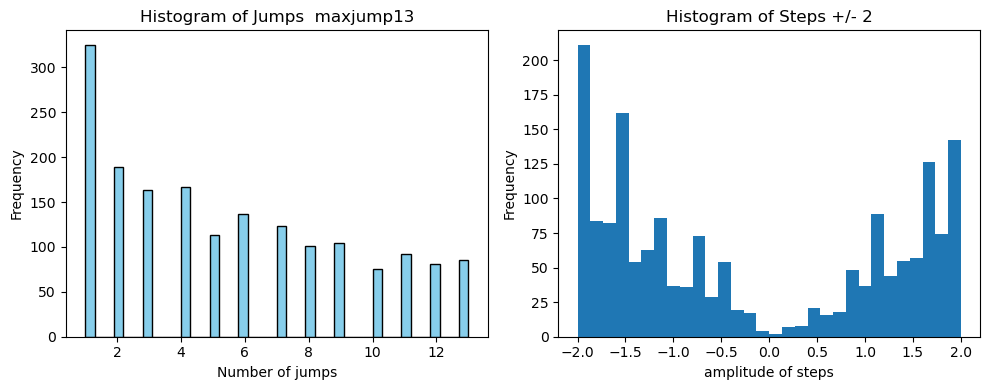

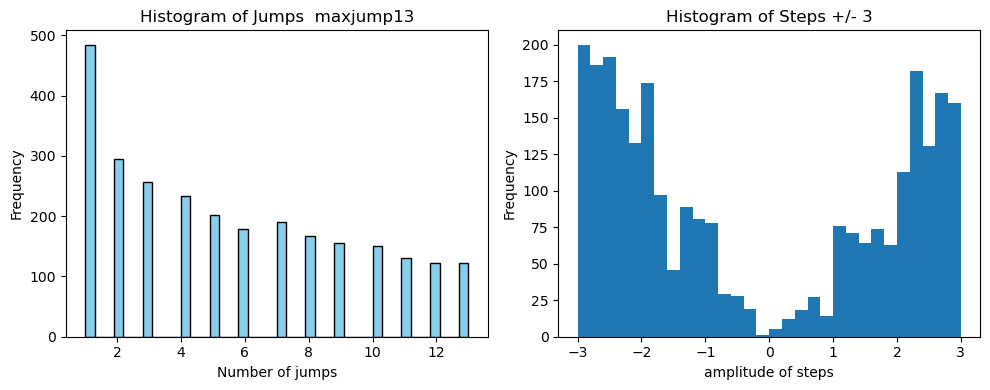

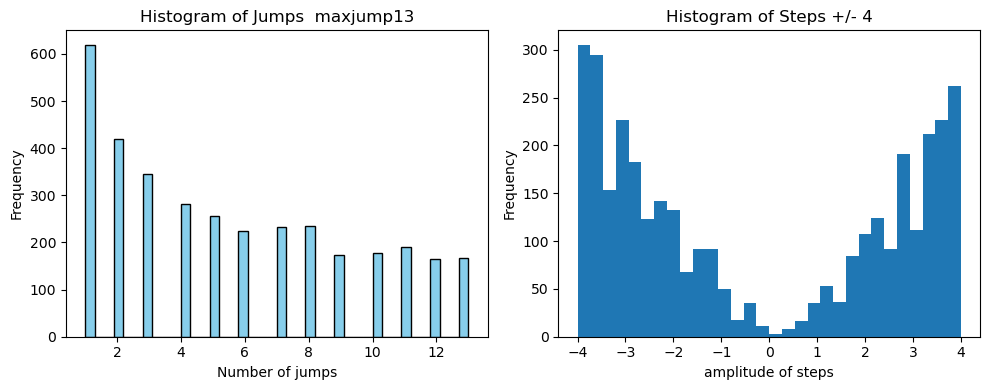

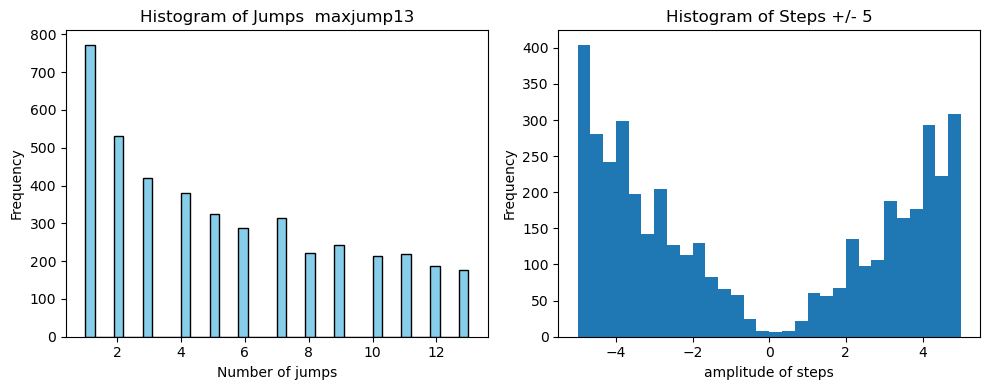

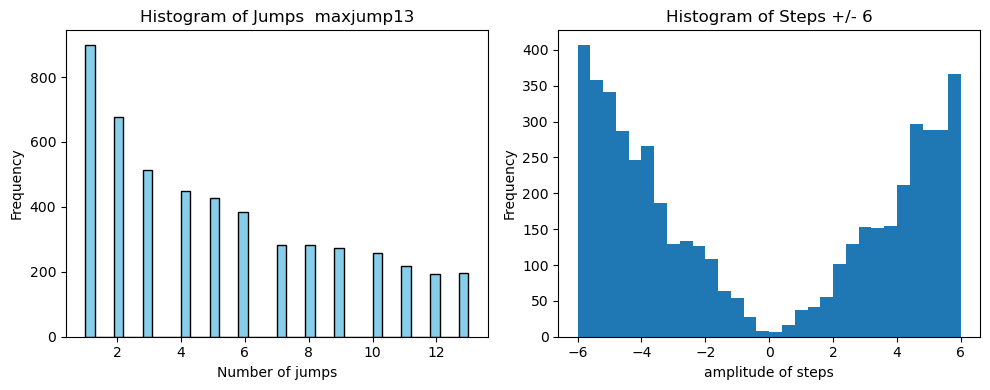

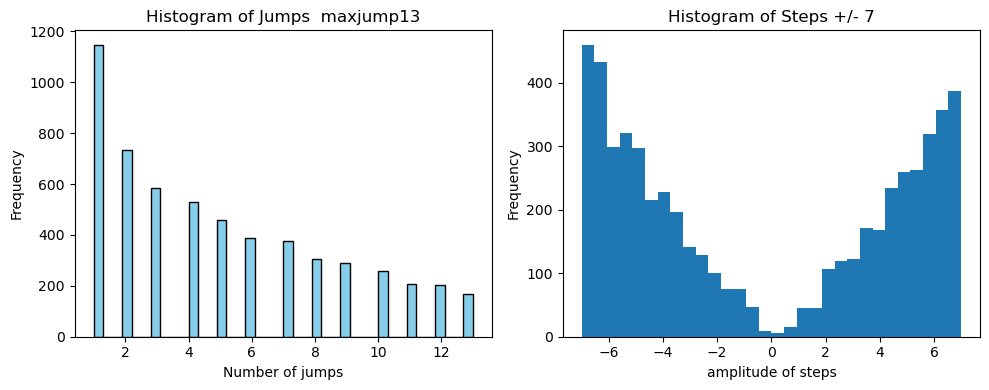

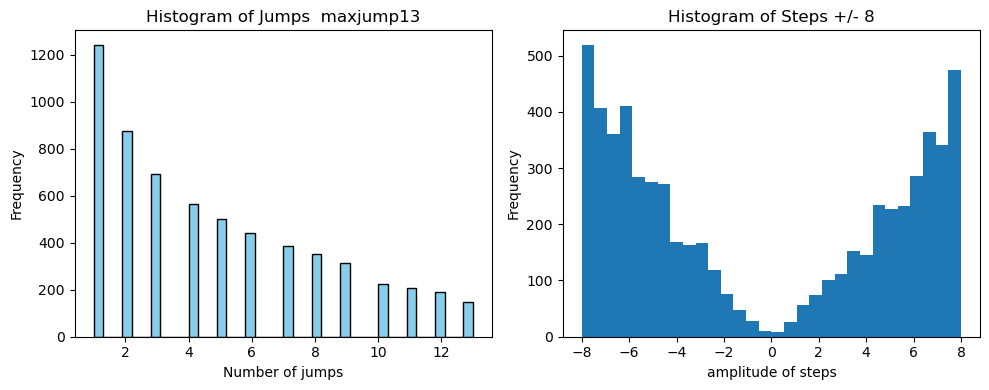

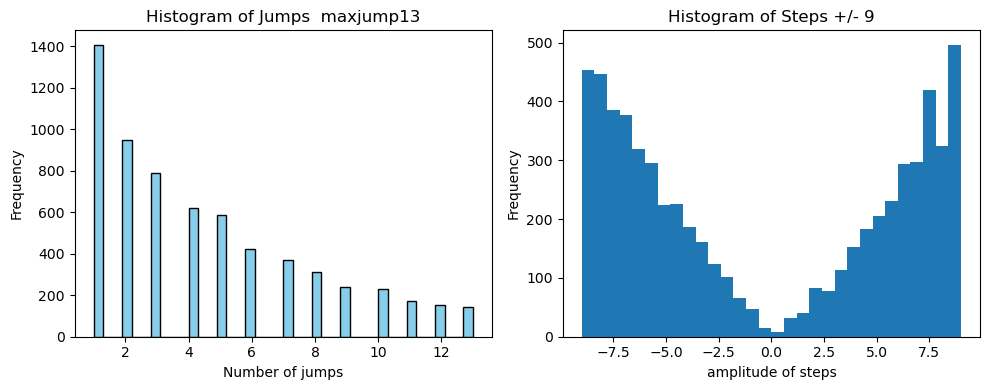

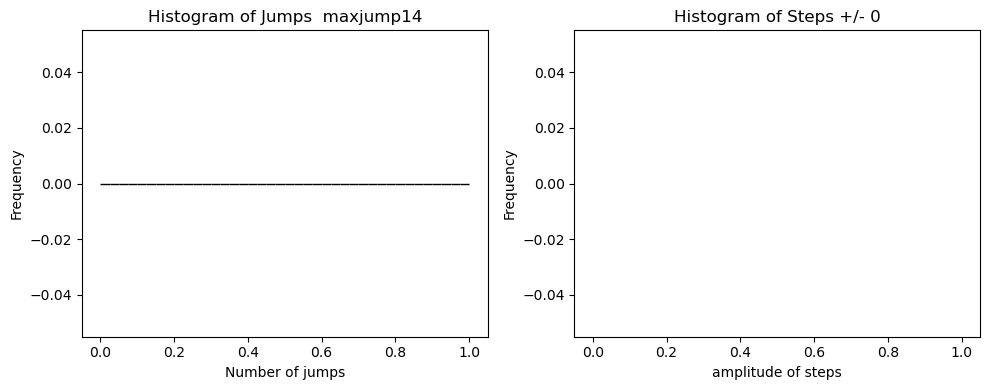

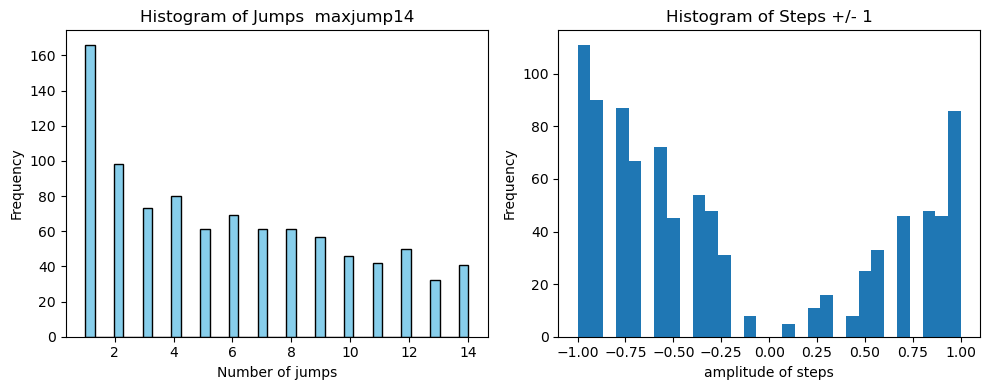

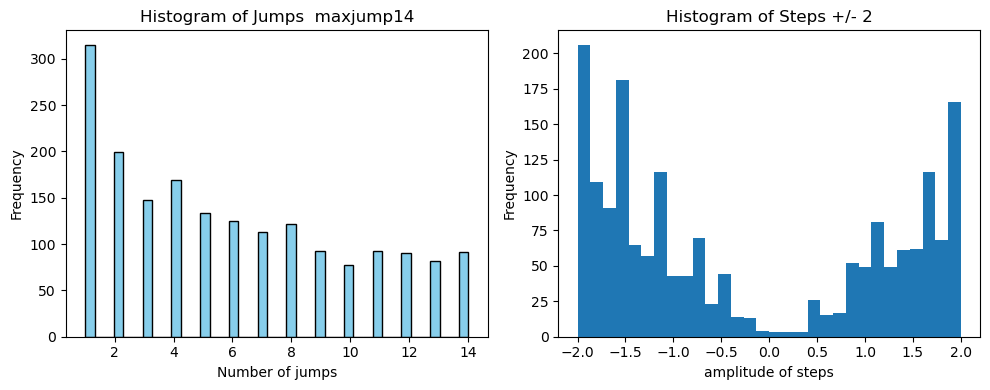

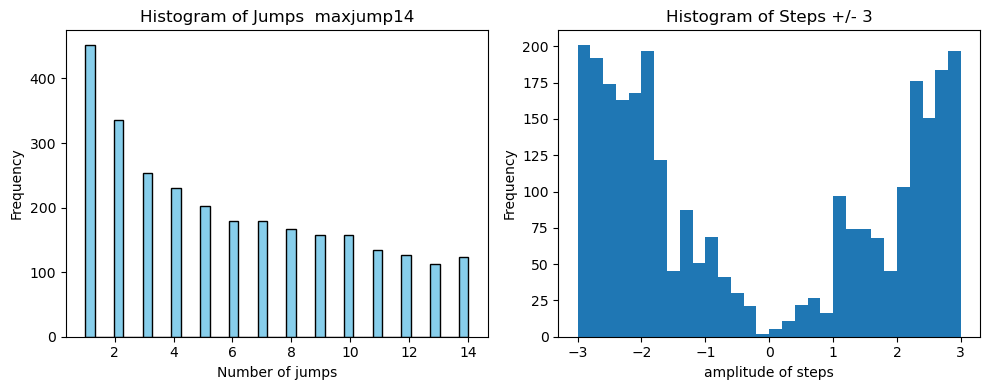

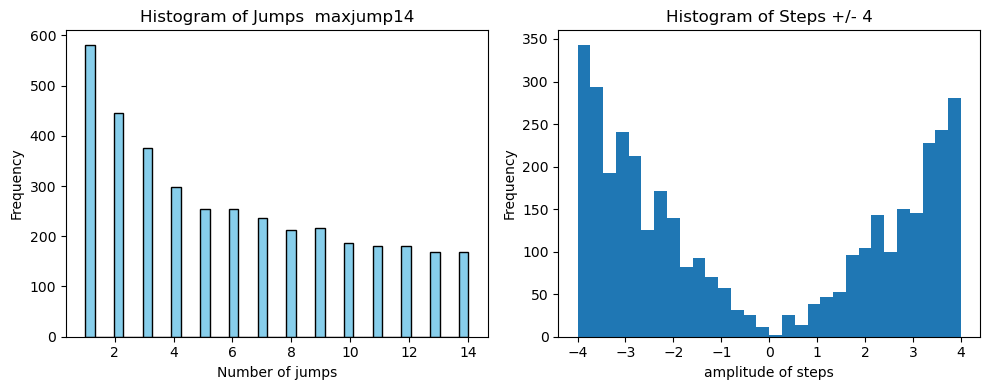

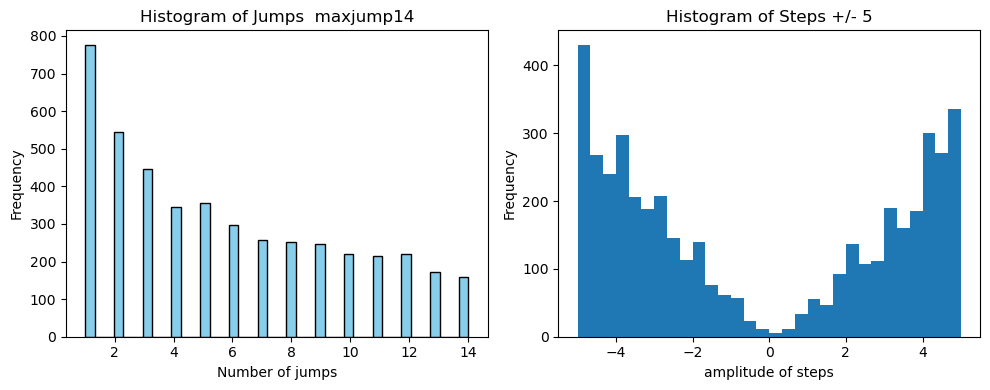

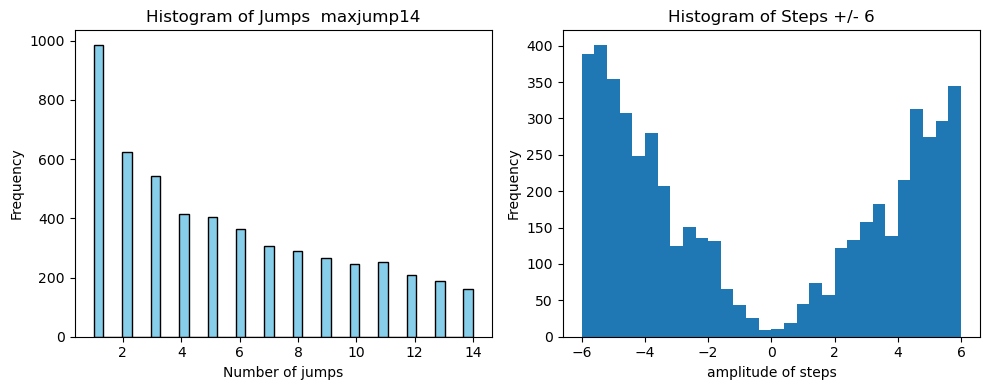

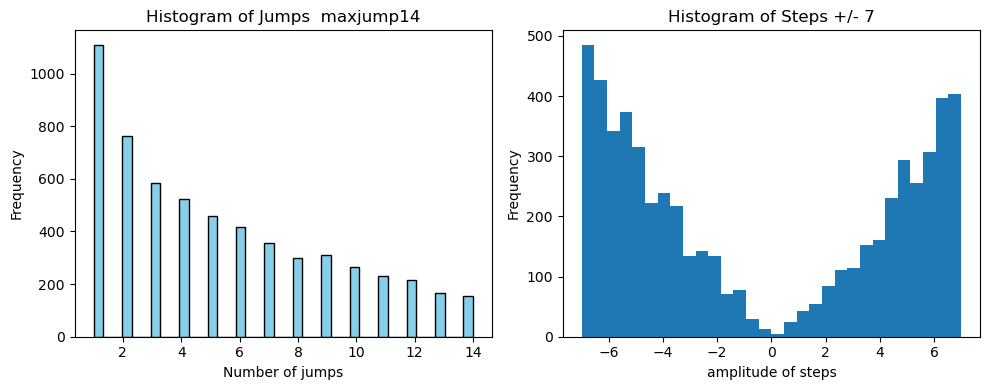

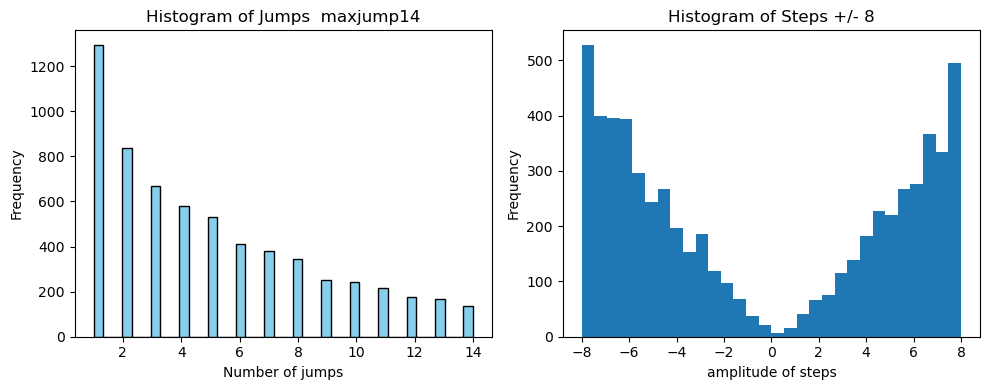

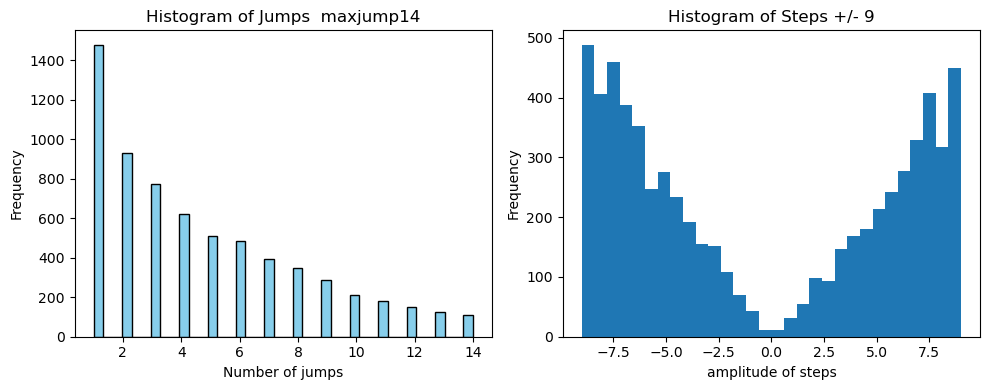

In [130]:
for maxs in range(5,15):
    for s in range(10):
        tot_j=[]
           
        tot_st=[]
    
        for k in range(10000):
            random_start=np.random.randint(0,360)
            # print(random_start)
        
            # random_step=np.random.randint(-20,20)
            # print(random_step)
            final_x, jumps, steps = jumps_until_inside(random_start, lower=lower, upper=upper,step=s, max_jumps=maxs)
            if steps!=0:
                tot_j.append(jumps)
                tot_st.append(steps)
            
            # if isinstance(steps, (list, np.ndarray)) and len(steps)>1:
            #     tot_st.extend(steps[-1])
            # else:
            #     tot_st.append(steps)
                
        tot_j = np.array(tot_j, dtype=float)  # float ensures no issues with None or nan
        # tot_st = np.array(tot_st, dtype=float)  # float ensures no issues with None or nan
        # print(tot_st)
        import matplotlib.pyplot as plt
        import numpy as np
        
        # Example: tot_j and tot_st are lists
        # Filter out any None, nan, or inf just in case
        
        # Histogram of jumps
        plt.figure(figsize=(10, 4))
        plt.subplot(1, 2, 1)
        plt.hist(tot_j, bins=40, color='skyblue', edgecolor='black')
        plt.title(f'Histogram of Jumps  maxjump{maxs}')
        plt.xlabel('Number of jumps')
        plt.ylabel('Frequency')
        
        # Histogram of steps
        plt.subplot(1, 2, 2)
        plt.hist(tot_st, bins=30)
        plt.title(f'Histogram of Steps +/- {s}')
        plt.xlabel('amplitude of steps')
        plt.ylabel('Frequency')
        
        plt.tight_layout()
        plt.show()


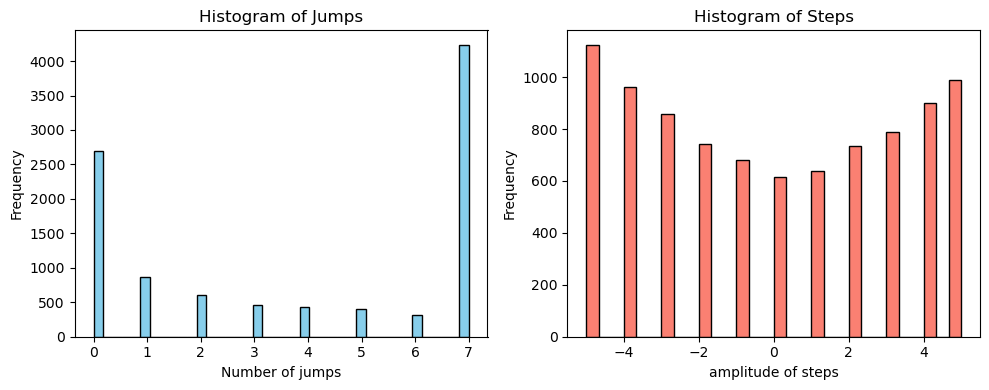

In [93]:
import matplotlib.pyplot as plt
import numpy as np

# Example: tot_j and tot_st are lists
# Filter out any None, nan, or inf just in case

# Histogram of jumps
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(tot_j, bins=40, color='skyblue', edgecolor='black')
plt.title('Histogram of Jumps')
plt.xlabel('Number of jumps')
plt.ylabel('Frequency')

# Histogram of steps
plt.subplot(1, 2, 2)
plt.hist(tot_st, bins=30, color='salmon', edgecolor='black')
plt.title('Histogram of Steps')
plt.xlabel('am of steps')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


(array([948.,  19.,   8.,   6.,  19.]),
 array([ 0. , 10.2, 20.4, 30.6, 40.8, 51. ]),
 <BarContainer object of 5 artists>)

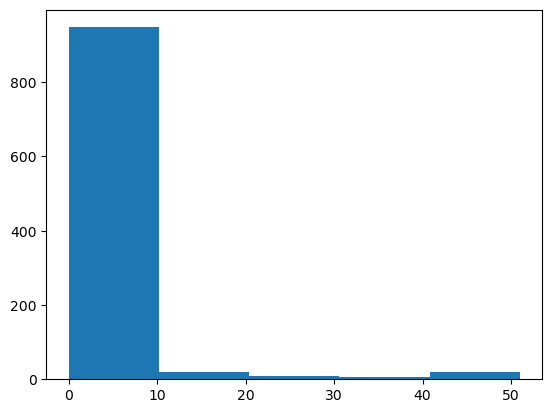

In [44]:
plt.hist(tot_j,bins=5)